# Previsão de Cota do Rio Madeira em Humaitá — comparação de modelos

Este notebook constrói a série diária contínua de cota (1991–2023) da estação **Humaitá (ANA 15630000)**, analisa os dados, preenche as lacunas por **interpolação** e compara famílias de modelos para previsão de curto prazo (**7 dias à frente**, e na seção 11 também **15 e 30 dias**):

| Família | Modelos |
|---|---|
| Baselines | Persistência, Naive sazonal, Climatologia, Persistência da anomalia |
| Estatístico | ARIMA sobre a anomalia sazonal |
| ML com lags | Ridge, Gradient Boosting (direto, um modelo por horizonte) |
| Deep learning (NeuralForecast) | LSTM, GRU, DLinear, N-HiTS, **PatchTST** |
| Ensemble | Média PatchTST + LSTM; stacking NNLS (seção 12) |
| DL com sazonalidade | Os mesmos modelos sobre a anomalia + exógenas de calendário (seção 12) |

Todos os modelos são avaliados **no mesmo conjunto de janelas de teste (2020–2023)** com as métricas usuais em hidrologia: RMSE, MAE, NSE e KGE.

> Unidade: a cota do Hidroweb vem em **centímetros**. Mantemos cm em todo o notebook.

## 0. Instalação e configuração

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn statsmodels scipy neuralforecast


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: /Users/sandro-teixeira/Downloads/deep-learning/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings, logging, os, time
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (13, 4.5)
plt.rcParams["figure.dpi"] = 100

SEED = 42
np.random.seed(SEED)

# Período de trabalho (ver README: livre de grandes lacunas e alinhado ao ciclo hidrológico)
START, END = "1991-01-01", "2023-12-31"

# Protocolo de previsão
H = 7             # horizonte: 7 dias à frente
INPUT_SIZE = 90   # janela de entrada dos modelos de deep learning (dias)
TEST_START = "2020-01-01"   # início nominal do teste
VAL_START  = "2016-01-01"   # início da validação (early stopping)

HUMAITA_CSV = "data/humaita/15630000_Cotas.csv"
SANTO_ANTONIO_CSV = "data/santo_antonio/15629000_Cotas.csv"

## 1. Carga dos dados brutos (Hidroweb)

Os CSVs do Hidroweb vêm em **ISO-8859-1**, separados por `;`, com 11 linhas de cabeçalho e no formato largo: uma linha por mês, colunas `Cota01…Cota31` e `Cota01Status…Cota31Status`.

Convertemos para o formato longo (uma linha por dia), mantendo apenas os registros **consistidos** (`NivelConsistencia == 2`) e o *status* de cada medição (1 = real, 2 = estimado pela ANA, 3 = duvidoso).

In [3]:
COTA_COLS = [f"Cota{d:02d}" for d in range(1, 32)]
STATUS_COLS = [c + "Status" for c in COTA_COLS]

def load_station(path, consistencia=2):
    raw = pd.read_csv(path, sep=";", encoding="latin-1", header=11, low_memory=False)
    df = raw[raw["NivelConsistencia"] == consistencia].copy()
    df["ref"] = pd.to_datetime(df["Data"], format="%d/%m/%Y", errors="coerce")

    vals = pd.melt(df, id_vars=["ref"], value_vars=COTA_COLS, var_name="col", value_name="cota")
    stat = pd.melt(df, id_vars=["ref"], value_vars=STATUS_COLS, var_name="col", value_name="status")
    vals["status"] = stat["status"].values          # mesma ordem de linhas
    vals["day"] = vals["col"].str[4:6].astype(int)
    vals["date"] = pd.to_datetime(
        dict(year=vals["ref"].dt.year, month=vals["ref"].dt.month, day=vals["day"]),
        errors="coerce",                            # 31/02, 31/04 etc. viram NaT
    )
    vals["cota"] = pd.to_numeric(vals["cota"], errors="coerce")

    out = (vals.dropna(subset=["date", "cota"])
               .sort_values("date")
               .drop_duplicates("date", keep="last")
               .set_index("date")[["cota", "status"]])
    print(f"{os.path.basename(path)}: {len(raw)} linhas brutas -> {len(out)} dias consistidos "
          f"({out.index.min().date()} a {out.index.max().date()})")
    return out

humaita_raw = load_station(HUMAITA_CSV)
santo_antonio_raw = load_station(SANTO_ANTONIO_CSV)
humaita_raw.head()

15630000_Cotas.csv: 2782 linhas brutas -> 27074 dias consistidos (1931-03-01 a 2023-12-31)
15629000_Cotas.csv: 226 linhas brutas -> 3226 dias consistidos (2011-02-26 a 2019-12-31)


,cota,status
date,,
1931-03-01,1257.0,1.0
1931-03-02,1257.0,1.0
1931-03-03,1249.0,1.0
1931-03-04,1247.0,1.0
1931-03-05,1249.0,1.0


## 2. Análise dos dados

### 2.1 Cobertura e lacunas na série completa (1931–2023)

In [4]:
def list_gaps(s: pd.Series) -> pd.DataFrame:
    # agrupa dias faltantes consecutivos em blocos
    miss = s[s.isna()].index.to_series()
    if miss.empty:
        return pd.DataFrame(columns=["inicio", "fim", "dias"])
    grp = (miss.diff() != pd.Timedelta("1D")).cumsum()
    return (miss.groupby(grp).agg(inicio="min", fim="max", dias="size")
                .reset_index(drop=True).sort_values("dias", ascending=False))

full_idx = pd.date_range(humaita_raw.index.min(), humaita_raw.index.max(), freq="D")
humaita_full = humaita_raw["cota"].reindex(full_idx)

gaps_full = list_gaps(humaita_full)
print(f"Dias faltantes em toda a série: {humaita_full.isna().sum()} de {len(humaita_full)}")
gaps_full.head(10)

Dias faltantes em toda a série: 6835 de 33909


,inicio,fim,dias
2,1949-03-01,1967-04-17,6622
3,1990-07-01,1990-11-09,132
0,1945-06-01,1945-06-30,30
1,1948-06-01,1948-06-30,30
4,2014-04-15,2014-04-30,16
5,2014-05-12,2014-05-16,5


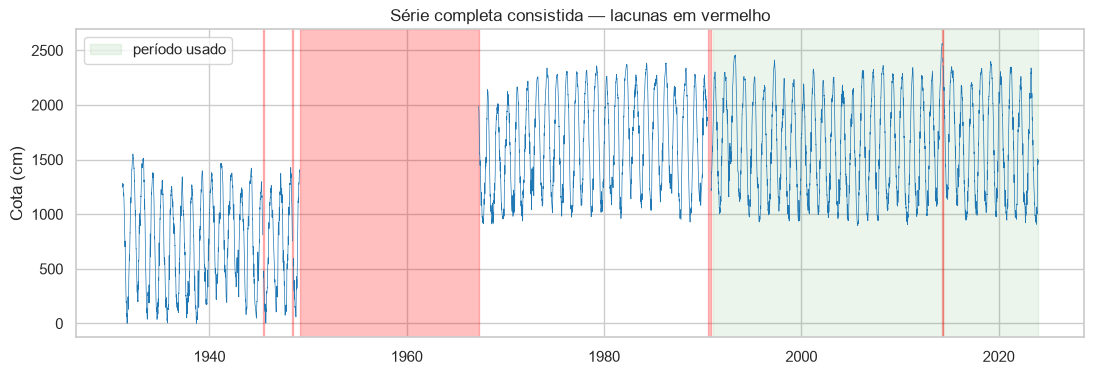

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(humaita_full.index, humaita_full.values, lw=0.5, color="#1f77b4")
for _, g in gaps_full.iterrows():
    ax.axvspan(g.inicio, g.fim, color="red", alpha=0.25)
ax.axvspan(pd.Timestamp(START), pd.Timestamp(END), color="green", alpha=0.08, label="período usado")
ax.set(title="Série completa consistida — lacunas em vermelho", ylabel="Cota (cm)")
ax.legend(loc="upper left")
plt.show()

### 2.2 Recorte 1991–2023 e status das medições

In [6]:
idx = pd.date_range(START, END, freq="D")
h = humaita_raw.reindex(idx)
y_raw = h["cota"].copy()

gaps = list_gaps(y_raw)
print(f"Dias no período: {len(idx)} | faltantes: {y_raw.isna().sum()}")
display(gaps)

status_map = {0: "Branco", 1: "Real", 2: "Estimado (ANA)", 3: "Duvidoso", 4: "Régua seca"}
print("\nStatus das medições no período:")
print(h["status"].map(status_map).value_counts(dropna=False))

Dias no período: 12053 | faltantes: 21


,inicio,fim,dias
0,2014-04-15,2014-04-30,16
1,2014-05-12,2014-05-16,5



Status das medições no período:
status
Real              11113
Estimado (ANA)      919
NaN                  21
Name: count, dtype: int64


Observações:
- Restam apenas **21 dias faltantes** em 33 anos, todos em abr/mai de 2014 (duas janelas: 16 e 5 dias).
- A própria ANA já marca ~900 dias como **estimados** — ou seja, a série "consistida" já contém imputação oficial. Nossa interpolação segue a mesma lógica.

### 2.3 Estatísticas descritivas e distribuição

,count,mean,std,min,25%,50%,75%,max
cota (cm),12032.0,1644.989029,453.443433,894.0,1204.0,1654.0,2065.0,2563.0


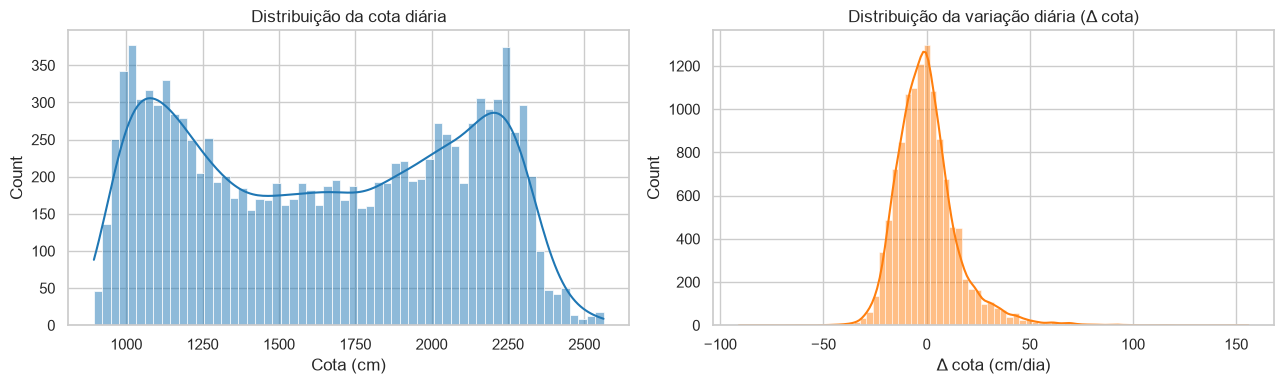

Variação diária: média |Δ| = 10.7 cm, p95 |Δ| = 29.0 cm, máx = 156 cm
Maiores variações diárias (subidas rápidas no início da estação chuvosa):


,|Δ| cm
1992-08-28,156.0
2020-12-12,125.0
2022-12-19,116.0
2011-12-18,115.0
1994-11-04,109.0


In [7]:
desc = y_raw.describe().to_frame("cota (cm)").T
display(desc)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_raw.dropna(), bins=60, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set(title="Distribuição da cota diária", xlabel="Cota (cm)")
sns.histplot(y_raw.diff().dropna(), bins=80, kde=True, ax=axes[1], color="#ff7f0e")
axes[1].set(title="Distribuição da variação diária (Δ cota)", xlabel="Δ cota (cm/dia)")
plt.tight_layout(); plt.show()

d = y_raw.diff()
print(f"Variação diária: média |Δ| = {d.abs().mean():.1f} cm, p95 |Δ| = {d.abs().quantile(.95):.1f} cm, máx = {d.abs().max():.0f} cm")
print("Maiores variações diárias (subidas rápidas no início da estação chuvosa):")
display(d.abs().sort_values(ascending=False).head(5).to_frame("|Δ| cm"))

A distribuição é **bimodal** (regime de cheia ≈ 2000–2500 cm e de seca ≈ 900–1300 cm), o que já indica que a sazonalidade domina a variância. A variação diária é pequena na maior parte do tempo (mediana de poucos cm), mas com cauda de subidas rápidas de >100 cm/dia — isso favorece a persistência como baseline e torna as transições de regime o ponto difícil da previsão.

### 2.4 Sazonalidade: ciclo anual

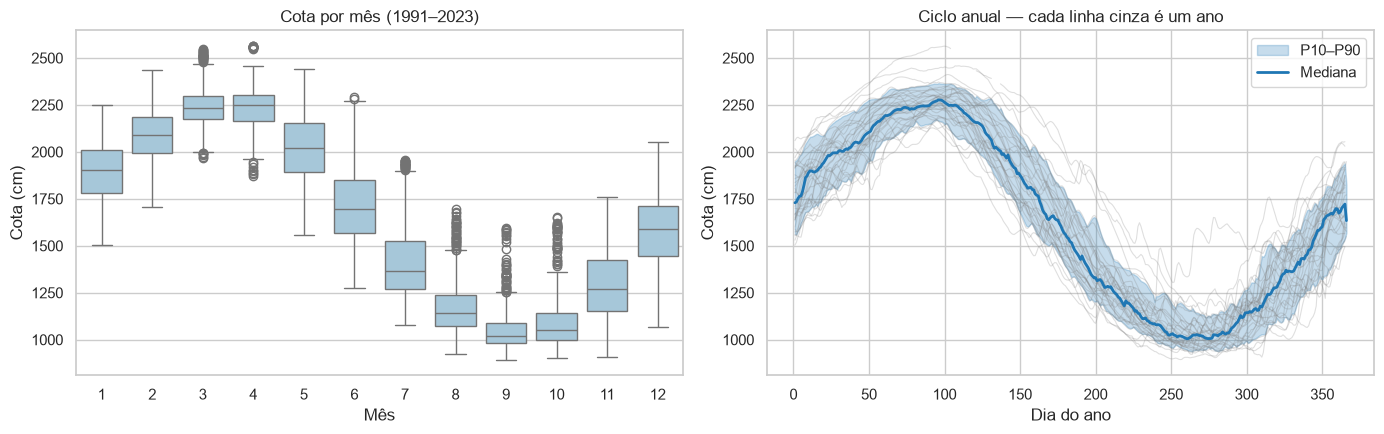

Mês do máximo anual: {2: 1, 3: 12, 4: 20}
Mês do mínimo anual: {8: 1, 9: 19, 10: 11, 11: 2}


In [8]:
df_y = y_raw.to_frame("cota")
df_y["ano"] = df_y.index.year
df_y["mes"] = df_y.index.month
df_y["doy"] = df_y.index.dayofyear

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df_y, x="mes", y="cota", ax=axes[0], color="#9ecae1")
axes[0].set(title="Cota por mês (1991–2023)", xlabel="Mês", ylabel="Cota (cm)")

piv = df_y.pivot_table(index="doy", columns="ano", values="cota")
axes[1].plot(piv.index, piv.values, color="gray", alpha=0.25, lw=0.8)
q = piv.quantile([0.1, 0.5, 0.9], axis=1).T
axes[1].fill_between(q.index, q[0.1], q[0.9], color="#1f77b4", alpha=0.25, label="P10–P90")
axes[1].plot(q.index, q[0.5], color="#1f77b4", lw=2, label="Mediana")
axes[1].set(title="Ciclo anual — cada linha cinza é um ano", xlabel="Dia do ano", ylabel="Cota (cm)")
axes[1].legend()
plt.tight_layout(); plt.show()

amax = df_y.groupby("ano")["cota"].idxmax().dt.month.value_counts().sort_index()
amin = df_y.groupby("ano")["cota"].idxmin().dt.month.value_counts().sort_index()
print("Mês do máximo anual:", amax.to_dict())
print("Mês do mínimo anual:", amin.to_dict())

O ciclo é extremamente regular: **cheia em março/abril, vazante até setembro/outubro**, subida a partir de novembro. A amplitude anual (~1300 cm) é muito maior que a variabilidade interanual, por isso qualquer modelo precisa "conhecer" o dia do ano — implicitamente (janela longa) ou explicitamente (climatologia / anomalia).

### 2.5 Autocorrelação e estacionariedade

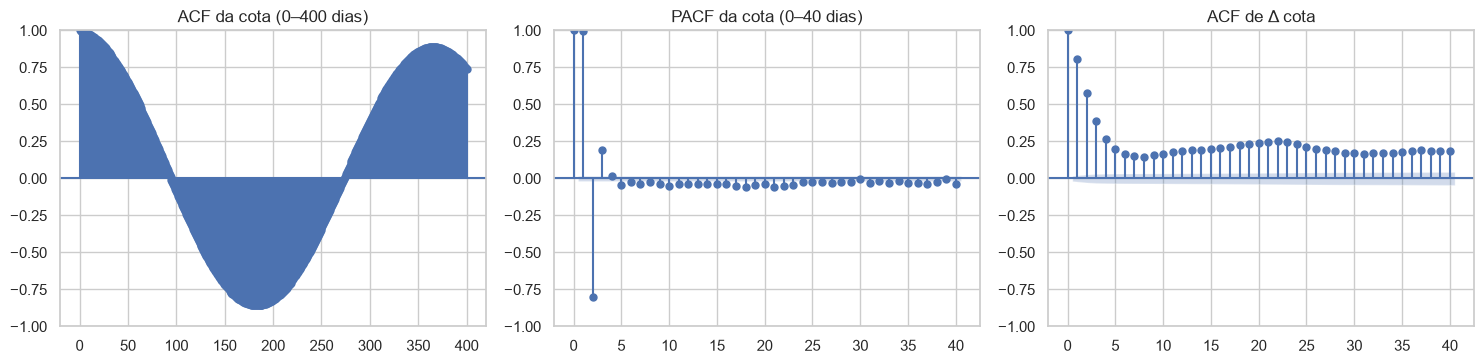

ADF cota   : estatística =  -13.196, p-valor = 0.0000
ADF Δ cota : estatística =   -9.093, p-valor = 0.0000


In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

y_tmp = y_raw.interpolate("time")   # só para ACF/ADF (21 pontos)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_acf(y_tmp, lags=400, ax=axes[0], alpha=None); axes[0].set_title("ACF da cota (0–400 dias)")
plot_pacf(y_tmp, lags=40, ax=axes[1], method="ywm"); axes[1].set_title("PACF da cota (0–40 dias)")
plot_acf(y_tmp.diff().dropna(), lags=40, ax=axes[2]); axes[2].set_title("ACF de Δ cota")
plt.tight_layout(); plt.show()

for name, s in [("cota", y_tmp), ("Δ cota", y_tmp.diff().dropna())]:
    stat, p, *_ = adfuller(s, autolag="AIC")
    print(f"ADF {name:7s}: estatística = {stat:8.3f}, p-valor = {p:.4f}")

- ACF com ciclo de ~365 dias (senoide) e PACF concentrada nos primeiros 1–2 lags: a série é **quase um AR(2) integrado com sazonalidade forte**.
- ADF rejeita raiz unitária na cota (a sazonalidade a mantém limitada) e com mais força na diferença. Mesmo assim, modelar a **anomalia** (cota − climatologia) tende a ser mais fácil do que a cota bruta.

### 2.6 Decomposição STL

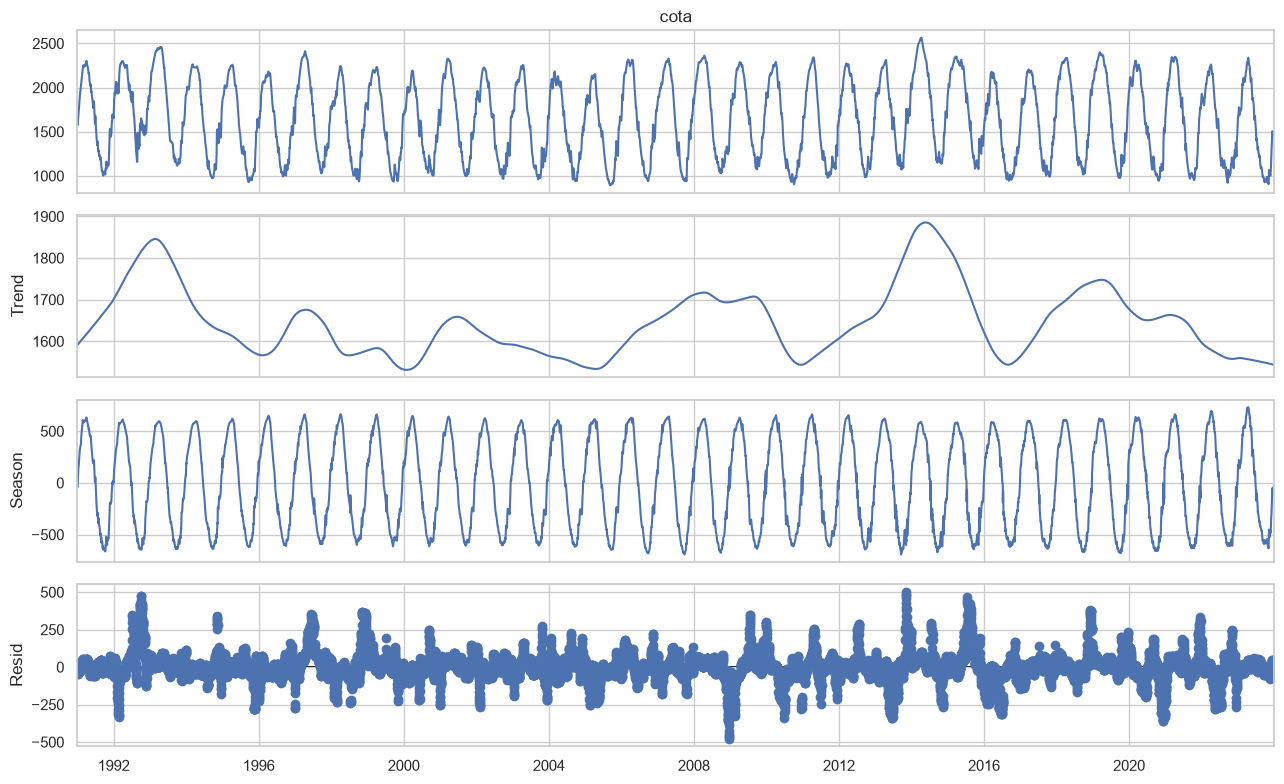

Desvio-padrão: série = 454 cm | sazonal = 443 cm | tendência = 83 cm | resíduo = 93 cm


In [10]:
from statsmodels.tsa.seasonal import STL

stl = STL(y_tmp, period=365, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(13, 8)
plt.tight_layout(); plt.show()

print(f"Desvio-padrão: série = {y_tmp.std():.0f} cm | sazonal = {stl.seasonal.std():.0f} cm | "
      f"tendência = {stl.trend.std():.0f} cm | resíduo = {stl.resid.std():.0f} cm")

### 2.7 Relação com a estação Santo Antônio (15629000)

Santo Antônio só tem dados consistidos entre 2011 e 2019, mas é a candidata natural para preencher as lacunas de 2014.

Dias em comum: 3210 (2011-02-26 a 2019-12-31)
Correlação de Pearson: 0.99971
Humaitá − Santo Antônio: média = -0.4 cm, desvio = 11.2 cm
Santo Antônio cobre 16 dos 21 dias faltantes de Humaitá


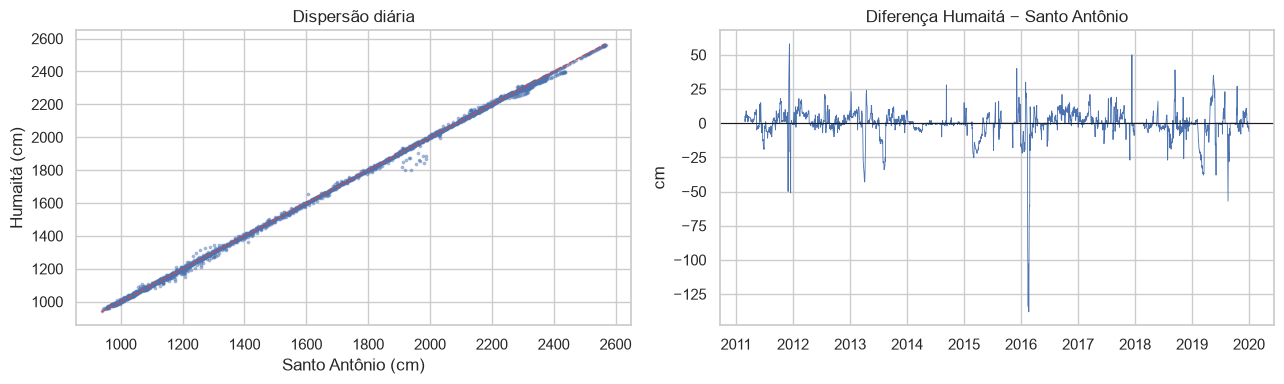

In [11]:
sa = santo_antonio_raw["cota"].reindex(idx)
both = pd.concat([y_raw, sa], axis=1, keys=["humaita", "santo_antonio"]).dropna()
diff_sa = both["humaita"] - both["santo_antonio"]

print(f"Dias em comum: {len(both)} ({both.index.min().date()} a {both.index.max().date()})")
print(f"Correlação de Pearson: {both.corr().iloc[0, 1]:.5f}")
print(f"Humaitá − Santo Antônio: média = {diff_sa.mean():.1f} cm, desvio = {diff_sa.std():.1f} cm")
print(f"Santo Antônio cobre {sa.loc[y_raw.isna()].notna().sum()} dos {y_raw.isna().sum()} dias faltantes de Humaitá")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(both["santo_antonio"], both["humaita"], s=3, alpha=0.4)
lim = [both.min().min(), both.max().max()]
axes[0].plot(lim, lim, "r--", lw=1); axes[0].set(xlabel="Santo Antônio (cm)", ylabel="Humaitá (cm)", title="Dispersão diária")
axes[1].plot(diff_sa.index, diff_sa.values, lw=0.6); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="Diferença Humaitá − Santo Antônio", ylabel="cm")
plt.tight_layout(); plt.show()

## 3. Preenchimento das lacunas

**Decisão do projeto: interpolação.** Antes de aplicar, quantificamos o erro esperado e comparamos com alternativas, para que a escolha seja justificada no artigo.

### 3.1 Quanto erro a interpolação introduz em lacunas de 5 e 16 dias?

Simulamos lacunas artificiais do mesmo tamanho em janelas reais (fora de 2014), preenchemos com cada método e medimos o erro contra os valores verdadeiros.

In [12]:
def fill(series, method):
    # interpola sobre a posição (índice diário regular) para evitar problemas numéricos
    # dos splines com índices de data em nanossegundos
    s = pd.Series(series.values, index=np.arange(len(series)), dtype=float)
    return pd.Series(s.interpolate(method).values, index=series.index)

def simulate_gap_error(s, gap_len, methods, n=300, seed=SEED):
    rng = np.random.default_rng(seed)
    s = s.dropna()
    starts = rng.choice(np.arange(30, len(s) - gap_len - 30), size=n, replace=False)
    rows = []
    for st in starts:
        # janela com 30 dias de contexto de cada lado
        w = s.iloc[st - 30: st + gap_len + 30].copy()
        truth = w.iloc[30: 30 + gap_len].to_numpy(copy=True)   # cópia: .values seria uma view
        w.iloc[30: 30 + gap_len] = np.nan
        for m in methods:
            est = fill(w, m).iloc[30: 30 + gap_len].values
            rows.append(dict(gap=gap_len, metodo=m,
                             rmse=np.sqrt(np.mean((est - truth) ** 2)), mae=np.mean(np.abs(est - truth))))
    return pd.DataFrame(rows)

methods = ["linear", "pchip", "akima", "cubic"]
sim = pd.concat([simulate_gap_error(y_raw, g, methods) for g in (5, 16)])
sim_tab = sim.groupby(["gap", "metodo"])[["rmse", "mae"]].mean().round(1)
sim_tab

rmse   mae
gap metodo            
5   akima    9.1   8.0
    cubic    8.1   7.2
    linear  11.6  10.5
    pchip    9.5   8.5
16  akima   28.1  23.5
    cubic   28.5  23.6
    linear  29.8  25.5
    pchip   27.8  23.3

### 3.2 Alternativa: transferir de Santo Antônio

Para a lacuna de 16 dias em abril/2014, Santo Antônio tem dados. Simulamos lacunas de 16 dias **no período em que as duas estações se sobrepõem** e comparamos interpolação vs. "cota de Santo Antônio + diferença média dos 7 dias anteriores".

In [13]:
def simulate_sa_transfer(h_s, sa_s, gap_len=16, n=200, seed=SEED):
    rng = np.random.default_rng(seed)
    both = pd.concat([h_s, sa_s], axis=1, keys=["h", "sa"]).dropna()
    one = pd.Timedelta("1D")
    # datas-fim cujos (gap_len + 7) dias anteriores são contínuos nas duas estações
    cont = both.index.to_series().diff().eq(one).rolling(gap_len + 7).sum().eq(gap_len + 7)
    ends = rng.choice(both.index[cont.values], size=min(n, int(cont.sum())), replace=False)
    rows = []
    for end in pd.DatetimeIndex(ends):
        g0 = end - one * (gap_len - 1)             # início da lacuna simulada
        pre0, pre1 = g0 - one * 7, g0 - one        # 7 dias anteriores (para o offset)
        truth = both.loc[g0:end, "h"].to_numpy(copy=True)
        offset = (both.loc[pre0:pre1, "h"] - both.loc[pre0:pre1, "sa"]).mean()
        est_sa = both.loc[g0:end, "sa"].values + offset
        w = h_s.loc[g0 - one * 30: end + one * 30].copy()
        w.loc[g0:end] = np.nan
        est_lin = fill(w, "linear").loc[g0:end].values
        rows.append(dict(metodo="linear", rmse=np.sqrt(np.mean((est_lin - truth) ** 2))))
        rows.append(dict(metodo="santo_antonio + offset", rmse=np.sqrt(np.mean((est_sa - truth) ** 2))))
    return pd.DataFrame(rows).groupby("metodo")["rmse"].agg(["mean", "median"]).round(1)

simulate_sa_transfer(y_raw, sa)

,mean,median
metodo,,
linear,33.4,24.6
santo_antonio + offset,8.4,4.9


### 3.3 As duas janelas de 2014 sob cada método

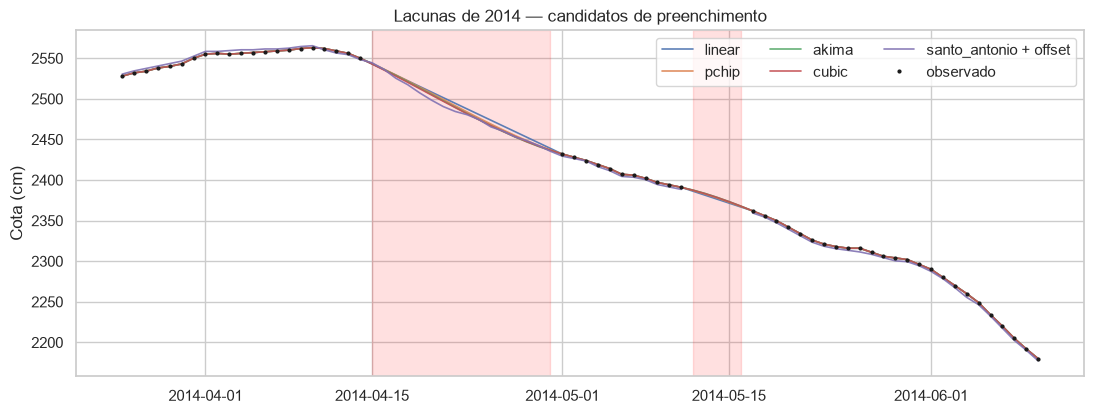

In [14]:
win = slice("2014-03-25", "2014-06-10")
cands = pd.DataFrame({m: fill(y_raw, m) for m in methods}).loc[win]
offset_apr = (y_raw - sa).loc["2014-04-08":"2014-04-14"].mean()
cands["santo_antonio + offset"] = (sa + offset_apr).loc[win]

fig, ax = plt.subplots(figsize=(13, 4.5))
for m in cands.columns:
    ax.plot(cands.index, cands[m], lw=1.2, alpha=0.9, label=m)
ax.plot(y_raw.loc[win].index, y_raw.loc[win], "k.", ms=4, label="observado")
for _, g in gaps.iterrows():
    ax.axvspan(g.inicio, g.fim, color="red", alpha=0.12)
ax.set(title="Lacunas de 2014 — candidatos de preenchimento", ylabel="Cota (cm)")
ax.legend(ncol=3); plt.show()

### 3.4 Série final

Aplicamos a **interpolação linear** (decisão do projeto). Ela é a mais simples e não depende de outra estação. Vale registrar, para o artigo, o que as simulações acima mostram:

- Para lacunas de 5 dias o erro é pequeno (~10 cm, comparável ao ruído entre estações). Para 16 dias sobe para ~30 cm de RMSE; splines (PCHIP/Akima) ganham pouco.
- A transferência de Santo Antônio (+ offset) tem erro **~4× menor** que a interpolação em lacunas de 16 dias. Se quiser mudar a decisão, basta trocar `y = y_raw.interpolate("time")` pela combinação `sa + offset` na janela de abril e manter interpolação na de maio (onde Santo Antônio não tem dados).

São 21 dias em 12.053 (0,17%), fora do período de teste, então o impacto sobre a comparação de modelos é desprezível. A coluna `imputed` marca os dias preenchidos.

In [15]:
y = y_raw.interpolate("time")
imputed = y_raw.isna()
assert y.isna().sum() == 0 and len(y) == len(idx)

serie = pd.DataFrame({"cota": y, "imputed": imputed})
serie.to_csv("data/humaita_cota_diaria_1991_2023.csv", index_label="date")
print(f"Série contínua: {len(serie)} dias, {imputed.sum()} imputados -> data/humaita_cota_diaria_1991_2023.csv")

Série contínua: 12053 dias, 21 imputados -> data/humaita_cota_diaria_1991_2023.csv


## 4. Protocolo de avaliação

- **Divisão temporal** (nunca aleatória): treino 1991–2015 · validação 2016–2019 (early stopping) · teste 2020–2023.
- **Horizonte** de 7 dias. No teste, a cada 7 dias fazemos uma previsão de 7 passos a partir do último valor observado (*rolling origin*, sem re-treino) — são ~208 janelas cobrindo cheia e seca de 4 anos.
- Todos os modelos usam exatamente as mesmas origens de previsão, então as métricas são diretamente comparáveis.

treino+val até 2020-01-05 | validação = 1461 dias | teste = 1456 dias | 208 janelas de 7 dias
primeira origem: 2020-01-05  última origem: 2023-12-24


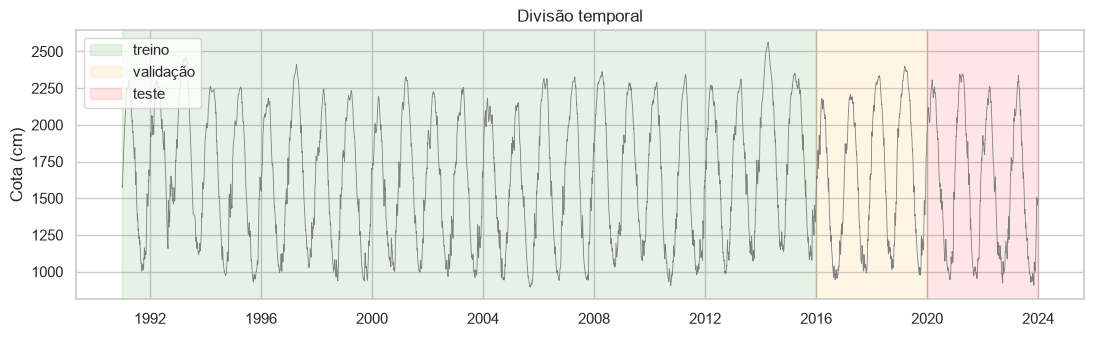

In [16]:
n = len(y)
n_test_nominal = (y.index >= TEST_START).sum()
TEST_SIZE = n_test_nominal - (n_test_nominal - H) % H        # múltiplo exigido pelo NeuralForecast
N_WINDOWS = (TEST_SIZE - H) // H + 1
VAL_SIZE = int(((y.index >= VAL_START) & (y.index < TEST_START)).sum())

train_end = y.index[n - TEST_SIZE - 1]         # última data observada antes do teste
cutoffs = pd.DatetimeIndex([train_end + pd.Timedelta(days=H * k) for k in range(N_WINDOWS)])
print(f"treino+val até {train_end.date()} | validação = {VAL_SIZE} dias | teste = {TEST_SIZE} dias | {N_WINDOWS} janelas de {H} dias")
print(f"primeira origem: {cutoffs[0].date()}  última origem: {cutoffs[-1].date()}")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(y.index, y, lw=0.6, color="gray")
ax.axvspan(y.index[0], pd.Timestamp(VAL_START), alpha=0.1, color="green", label="treino")
ax.axvspan(pd.Timestamp(VAL_START), train_end, alpha=0.1, color="orange", label="validação")
ax.axvspan(train_end, y.index[-1], alpha=0.1, color="red", label="teste")
ax.legend(loc="upper left"); ax.set(title="Divisão temporal", ylabel="Cota (cm)"); plt.show()

### 4.1 Métricas

In [17]:
def rmse(y_true, y_pred): return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
def mae(y_true, y_pred):  return float(np.mean(np.abs(y_true - y_pred)))
def nse(y_true, y_pred):  return float(1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2))
def kge(y_true, y_pred):
    r = np.corrcoef(y_true, y_pred)[0, 1]
    alpha = y_pred.std() / y_true.std()
    beta = y_pred.mean() / y_true.mean()
    return float(1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2))

METRICS = {"RMSE": rmse, "MAE": mae, "NSE": nse, "KGE": kge}

def evaluate(cv: pd.DataFrame, models) -> pd.DataFrame:
    # cv tem colunas ds, cutoff, y e uma coluna por modelo
    rows = {}
    for m in models:
        rows[m] = {k: f(cv["y"].values, cv[m].values) for k, f in METRICS.items()}
    return pd.DataFrame(rows).T.sort_values("RMSE")

def evaluate_by(cv, models, key, metric="RMSE"):
    # métrica por grupo (horizonte, regime...) — uma linha por valor de `key`
    out = {}
    for k, g in cv.groupby(key, observed=True):
        out[k] = {m: METRICS[metric](g["y"].values, g[m].values) for m in models}
    return pd.DataFrame(out).T.rename_axis(key)

def evaluate_by_horizon(cv, models, metric="RMSE"):
    return evaluate_by(cv.assign(h=(cv["ds"] - cv["cutoff"]).dt.days), models, "h", metric)

### 4.2 Estrutura comum das previsões

`cv` terá uma linha por (origem, dia previsto), com a cota observada e uma coluna por modelo — o mesmo formato que o `cross_validation` do NeuralForecast devolve.

In [18]:
def make_cv(cutoffs, H):
    rows = []
    for c in cutoffs:
        ds = pd.date_range(c + pd.Timedelta(days=1), periods=H, freq="D")
        rows.append(pd.DataFrame({"cutoff": c, "ds": ds, "y": y.loc[ds].values}))
    return pd.concat(rows, ignore_index=True)

cv = make_cv(cutoffs, H)
cv.head(8)

,cutoff,ds,y
0,2020-01-05,2020-01-06,2033.0
1,2020-01-05,2020-01-07,2049.0
2,2020-01-05,2020-01-08,2066.0
3,2020-01-05,2020-01-09,2079.0
4,2020-01-05,2020-01-10,2094.0
5,2020-01-05,2020-01-11,2104.0
6,2020-01-05,2020-01-12,2111.0
7,2020-01-12,2020-01-13,2116.0


## 5. Baselines

Em rios grandes a cota muda pouco de um dia para o outro, então a **persistência** (amanhã = hoje) é difícil de bater em horizontes curtos. Qualquer modelo que não a supere não deve ir para o artigo.

- **Persistência:** $\hat y_{t+h} = y_t$
- **Naive sazonal:** $\hat y_{t+h} = y_{t+h-365}$
- **Climatologia:** média por dia do ano (calculada só no treino)
- **Persistência da anomalia:** $\hat y_{t+h} = \text{clim}(t+h) + (y_t - \text{clim}(t))$ — persiste o desvio em relação ao ciclo médio

In [19]:
# Climatologia suavizada por dia do ano, usando só treino+validação
train_series = y.loc[:train_end]
clim_doy = train_series.groupby(train_series.index.dayofyear).mean()
clim_doy = clim_doy.reindex(range(1, 367)).interpolate()
# suavização circular de 15 dias
_c = pd.concat([clim_doy.iloc[-15:], clim_doy, clim_doy.iloc[:15]]).rolling(15, center=True).mean()
clim_doy = _c.iloc[15:-15]; clim_doy.index = range(1, 367)
clim = pd.Series(clim_doy.loc[y.index.dayofyear].values, index=y.index)   # climatologia alinhada à série
anom = y - clim

cv["Persistencia"] = y.loc[cv["cutoff"]].values
cv["NaiveSazonal"] = y.loc[cv["ds"] - pd.Timedelta(days=365)].values
cv["Climatologia"] = clim.loc[cv["ds"]].values
cv["PersistAnomalia"] = clim.loc[cv["ds"]].values + anom.loc[cv["cutoff"]].values

BASELINES = ["Persistencia", "NaiveSazonal", "Climatologia", "PersistAnomalia"]
evaluate(cv, BASELINES).round(3)

,RMSE,MAE,NSE,KGE
PersistAnomalia,45.792,32.391,0.990,0.994
Persistencia,57.096,40.497,0.985,0.993
Climatologia,133.384,105.189,0.919,0.898
NaiveSazonal,179.640,144.394,0.854,0.923


## 6. Modelo estatístico: ARIMA sobre a anomalia

SARIMA com período 365 é inviável em dados diários. A alternativa clássica é **remover a climatologia** e ajustar um ARIMA à anomalia. Ajustamos uma vez no treino e, em cada origem do teste, apenas atualizamos o estado do filtro (`apply`), sem re-estimar parâmetros.

In [20]:
from statsmodels.tsa.arima.model import ARIMA

anom_train = anom.loc[:train_end]
t0 = time.time()
orders = [(1, 1, 0), (2, 1, 0), (1, 1, 1), (2, 1, 1), (3, 1, 0)]
fits = {o: ARIMA(anom_train.values, order=o).fit() for o in orders}
best_order = min(fits, key=lambda o: fits[o].aic)
arima_res = fits[best_order]
print(f"Melhor ordem por AIC: {best_order} (AIC {arima_res.aic:.0f}) em {time.time()-t0:.0f}s")

preds = []
for c in cutoffs:
    hist = anom.loc[:c].values
    fc = arima_res.apply(hist).forecast(H)
    preds.append(fc)
cv["ARIMA_anom"] = np.concatenate(preds) + clim.loc[cv["ds"]].values
evaluate(cv, BASELINES + ["ARIMA_anom"]).round(3)

Melhor ordem por AIC: (2, 1, 1) (AIC 73203) em 1s


,RMSE,MAE,NSE,KGE
ARIMA_anom,45.285,30.543,0.991,0.994
PersistAnomalia,45.792,32.391,0.990,0.994
Persistencia,57.096,40.497,0.985,0.993
Climatologia,133.384,105.189,0.919,0.898
NaiveSazonal,179.640,144.394,0.854,0.923


## 7. Machine learning com features de lags (estratégia direta)

Um modelo por horizonte $h \in \{1..7\}$. Features na origem $t$: últimos 30 valores, variações recentes, anomalia atual, dia do ano em seno/cosseno e a climatologia do dia-alvo. Alvo: **anomalia** em $t+h$ (o modelo aprende o desvio; somamos a climatologia depois).

In [21]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_LAGS = 30

def build_features(t_index):
    # t_index: datas de origem
    pos = y.index.get_indexer(t_index)
    Y = y.values; A = anom.values
    F = {}
    for k in range(N_LAGS):
        F[f"lag{k}"] = Y[pos - k]
    F["anom0"] = A[pos]
    F["d1"] = Y[pos] - Y[pos - 1]
    F["d7"] = Y[pos] - Y[pos - 7]
    F["d30"] = Y[pos] - Y[pos - 30]
    doy = t_index.dayofyear.values
    F["sin"] = np.sin(2 * np.pi * doy / 365.25); F["cos"] = np.cos(2 * np.pi * doy / 365.25)
    return pd.DataFrame(F, index=t_index)

def add_target_clim(X, h):
    X = X.copy()
    X["clim_target"] = clim_doy.loc[(X.index + pd.Timedelta(days=h)).dayofyear].values
    return X

train_origins = y.index[N_LAGS + 1: y.index.get_loc(train_end) - H + 1]   # origens cujo alvo t+H ainda está no treino
X_train_base = build_features(train_origins)
X_test_base = build_features(cutoffs)

ml_models = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "GradBoost": lambda: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                       l2_regularization=1.0, random_state=SEED),
}
t0 = time.time()
for name, make in ml_models.items():
    pred = np.zeros((len(cutoffs), H))
    for h_ in range(1, H + 1):
        Xtr = add_target_clim(X_train_base, h_)
        ytr = anom.loc[train_origins + pd.Timedelta(days=h_)].values
        model = make().fit(Xtr, ytr)
        Xte = add_target_clim(X_test_base, h_)
        pred[:, h_ - 1] = model.predict(Xte) + Xte["clim_target"].values
    cv[name] = pred.reshape(-1)
    print(f"{name}: {time.time()-t0:.0f}s")

ML = list(ml_models)
evaluate(cv, BASELINES + ["ARIMA_anom"] + ML).round(3)

Ridge: 0s


GradBoost: 13s


,RMSE,MAE,NSE,KGE
Ridge,43.796,29.908,0.991,0.990
GradBoost,45.073,30.474,0.991,0.981
ARIMA_anom,45.285,30.543,0.991,0.994
PersistAnomalia,45.792,32.391,0.990,0.994
Persistencia,57.096,40.497,0.985,0.993
Climatologia,133.384,105.189,0.919,0.898
NaiveSazonal,179.640,144.394,0.854,0.923


## 8. Deep learning com NeuralForecast

Todos os modelos recebem a mesma janela de entrada (`INPUT_SIZE` dias), normalização padrão por janela e early stopping na validação. São **univariados** (só a cota), para uma comparação justa entre arquiteturas.

| Modelo | Ideia |
|---|---|
| **LSTM / GRU** | recorrentes — o padrão da literatura hidrológica |
| **DLinear** | modelo linear com decomposição tendência/sazonal; baseline forte de Zeng et al. (2022) |
| **N-HiTS** | MLP hierárquico multi-escala; muito competitivo em séries univariadas |
| **PatchTST** | Transformer sobre *patches* da série (Nie et al., 2023) |

> Treino em CPU: ~1 min por modelo com `MAX_STEPS = 1000` (early stopping costuma parar antes). Aumente para resultados finais.
>
> **Atenção com as RNNs:** com a configuração padrão do NeuralForecast (`recurrent=False`, 64 unidades, 2 camadas) LSTM e GRU ficaram *piores que a persistência* (RMSE ≈ 70 cm). Com decodificação recorrente, 128 unidades e 1 camada o LSTM caiu para ≈ 54 cm. Ou seja: o ranking entre arquiteturas é sensível a hiperparâmetros — uma busca sistemática (seção 10) é obrigatória antes de qualquer conclusão para o artigo.

In [22]:
import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import LSTM, GRU, DLinear, NHITS, PatchTST

MAX_STEPS = 1000
common = dict(h=H, input_size=INPUT_SIZE, max_steps=MAX_STEPS, val_check_steps=25,
              early_stop_patience_steps=6, scaler_type="standard", random_seed=SEED,
              batch_size=64, enable_progress_bar=False, enable_model_summary=False, logger=False, accelerator="cpu")

# RNNs: `recurrent=True` usa decodificação recorrente (seq2seq clássico). O padrão do NeuralForecast 3.x
# (decoder MLP) ficou pior que a persistência nos nossos testes; esta configuração foi a melhor de ~10 testadas.
rnn = dict(encoder_hidden_size=128, encoder_n_layers=1, decoder_hidden_size=128, learning_rate=5e-4, recurrent=True)
dl_models = [
    LSTM(**rnn, **common),
    GRU(**rnn, **common),
    DLinear(learning_rate=1e-3, **common),
    NHITS(learning_rate=1e-3, **common),
    PatchTST(patch_len=16, stride=8, hidden_size=64, n_heads=4, encoder_layers=2,
             learning_rate=1e-4, **common),
]

nf_df = pd.DataFrame({"unique_id": "humaita", "ds": y.index, "y": y.values})
nf = NeuralForecast(models=dl_models, freq="D")

t0 = time.time()
cv_dl = nf.cross_validation(df=nf_df, val_size=VAL_SIZE, test_size=TEST_SIZE, step_size=H, n_windows=None)
print(f"Treino + previsões: {(time.time()-t0)/60:.1f} min")

# garante que as origens são exatamente as mesmas dos outros modelos
assert (cv_dl["cutoff"].unique() == cutoffs.values).all()
DL = [m.__class__.__name__ for m in dl_models]
cv = cv.drop(columns=[c for c in DL if c in cv], errors="ignore").merge(
    cv_dl[["ds", "cutoff"] + DL], on=["ds", "cutoff"], how="left")
evaluate(cv, DL).round(3)

2026-09-28 17:49:53,635	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-09-28 17:49:54,177	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


... (22 outputs left out)

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


Treino + previsões: 2.7 min


,RMSE,MAE,NSE,KGE
PatchTST,48.231,32.156,0.989,0.993
DLinear,48.324,31.843,0.989,0.991
GRU,53.765,35.344,0.987,0.986
LSTM,54.305,37.256,0.987,0.972
NHITS,56.450,37.921,0.986,0.990


### 8.1 Ensemble PatchTST + LSTM

In [23]:
cv["Ensemble_PatchTST_LSTM"] = (cv["PatchTST"] + cv["LSTM"]) / 2
cv["Ensemble_DL"] = cv[DL].mean(axis=1)
ENS = ["Ensemble_PatchTST_LSTM", "Ensemble_DL"]
evaluate(cv, DL + ENS).round(3)

,RMSE,MAE,NSE,KGE
PatchTST,48.231,32.156,0.989,0.993
DLinear,48.324,31.843,0.989,0.991
Ensemble_DL,49.027,32.488,0.989,0.988
Ensemble_PatchTST_LSTM,49.381,33.115,0.989,0.984
GRU,53.765,35.344,0.987,0.986
LSTM,54.305,37.256,0.987,0.972
NHITS,56.450,37.921,0.986,0.990


## 9. Resultados

In [24]:
ALL = BASELINES + ["ARIMA_anom"] + ML + DL + ENS
results = evaluate(cv, ALL).round(2)
results.to_csv("results_forecast_h7.csv")
results.style.background_gradient(subset=["RMSE", "MAE"], cmap="RdYlGn_r").background_gradient(subset=["NSE", "KGE"], cmap="RdYlGn")

,RMSE,MAE,NSE,KGE
Ridge,43.800000,29.910000,0.990000,0.990000
GradBoost,45.070000,30.470000,0.990000,0.980000
ARIMA_anom,45.290000,30.540000,0.990000,0.990000
PersistAnomalia,45.790000,32.390000,0.990000,0.990000
PatchTST,48.230000,32.160000,0.990000,0.990000
DLinear,48.320000,31.840000,0.990000,0.990000
Ensemble_DL,49.030000,32.490000,0.990000,0.990000
Ensemble_PatchTST_LSTM,49.380000,33.110000,0.990000,0.980000
GRU,53.760000,35.340000,0.990000,0.990000
LSTM,54.310000,37.260000,0.990000,0.970000


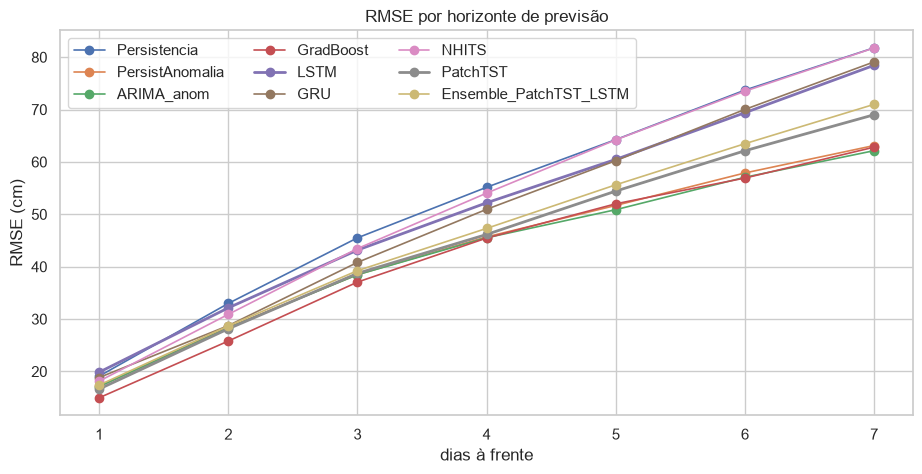

,Persistencia,NaiveSazonal,Climatologia,PersistAnomalia,ARIMA_anom,Ridge,GradBoost,LSTM,GRU,DLinear,NHITS,PatchTST,Ensemble_PatchTST_LSTM,Ensemble_DL
h,,,,,,,,,,,,,,
1,19.1,180.0,132.6,17.1,17.1,16.8,15.0,19.9,18.8,16.6,18.1,16.6,17.4,17.0
2,33.0,180.1,132.4,28.4,28.3,27.4,25.8,32.1,28.7,27.2,30.9,28.1,28.7,27.9
3,45.5,179.1,133.0,38.5,38.5,36.9,37.1,43.2,40.8,37.6,43.5,38.7,39.2,38.7
4,55.2,178.3,133.0,45.7,45.5,43.5,45.5,52.2,51.0,45.8,54.0,46.1,47.3,47.1
5,64.3,178.7,133.6,51.7,50.9,49.1,52.0,60.5,60.2,53.9,64.2,54.4,55.6,55.2
6,73.7,179.7,134.1,57.9,57.1,55.5,56.9,69.4,70.0,62.6,73.5,62.1,63.5,63.2
7,81.8,181.6,134.9,63.1,62.1,60.4,62.8,78.4,79.1,70.7,81.8,69.0,71.0,70.6


In [25]:
byh = evaluate_by_horizon(cv, ALL, "RMSE")
fig, ax = plt.subplots(figsize=(11, 5))
for m in ["Persistencia", "PersistAnomalia", "ARIMA_anom", "GradBoost", "LSTM", "GRU", "NHITS", "PatchTST", "Ensemble_PatchTST_LSTM"]:
    ax.plot(byh.index, byh[m], marker="o", label=m, lw=2 if m in ("PatchTST", "LSTM") else 1.2)
ax.set(title="RMSE por horizonte de previsão", xlabel="dias à frente", ylabel="RMSE (cm)")
ax.legend(ncol=3); plt.show()
byh.round(1)

### 9.1 Previsões no teste — cheia e seca

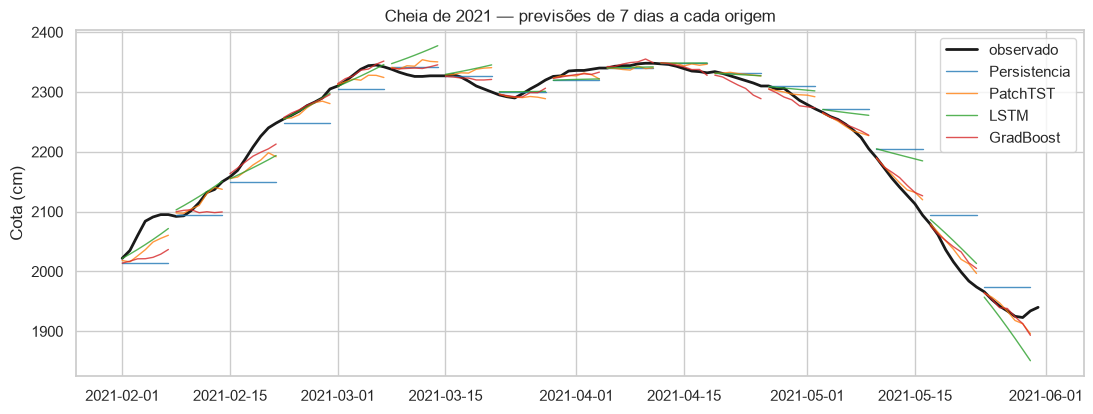

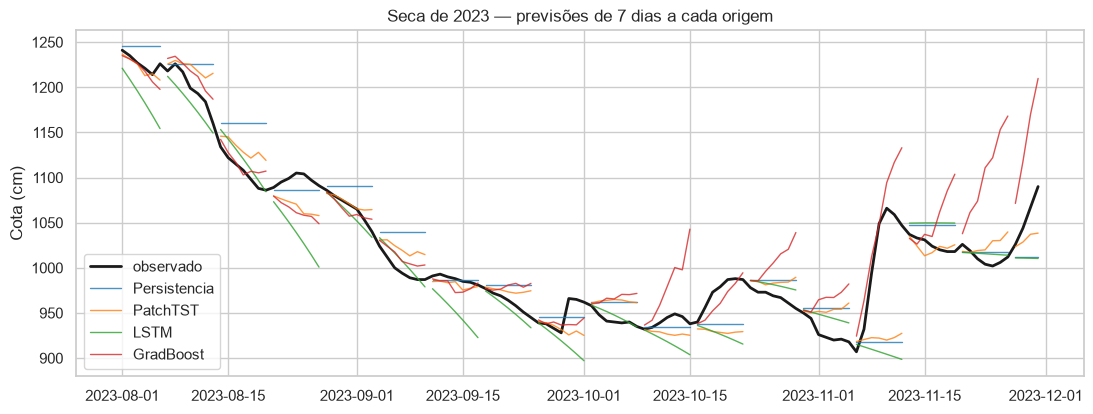

In [26]:
def plot_window(cv, start, end, models, title):
    sub = cv[(cv["ds"] >= start) & (cv["ds"] <= end)]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(sub["ds"], sub["y"], "k-", lw=2, label="observado")
    for i, m in enumerate(models):
        for j, (_, g) in enumerate(sub.groupby("cutoff")):
            ax.plot(g["ds"], g[m], lw=1, alpha=0.8, color=plt.cm.tab10(i), label=m if j == 0 else None)
    ax.set(title=title, ylabel="Cota (cm)"); ax.legend(); plt.show()

show = ["Persistencia", "PatchTST", "LSTM", "GradBoost"]
plot_window(cv, "2021-02-01", "2021-05-31", show, "Cheia de 2021 — previsões de 7 dias a cada origem")
plot_window(cv, "2023-08-01", "2023-11-30", show, "Seca de 2023 — previsões de 7 dias a cada origem")

### 9.2 Erro por regime hidrológico

In [27]:
cv["mes"] = cv["ds"].dt.month
regime = pd.cut(cv["mes"], bins=[0, 2, 5, 8, 10, 12],
                labels=["subida (jan-fev)", "cheia (mar-mai)", "vazante (jun-ago)", "seca (set-out)", "subida (nov-dez)"])
evaluate_by(cv.assign(regime=regime), ["Persistencia", "PersistAnomalia", "GradBoost", "LSTM", "GRU", "PatchTST", "Ensemble_PatchTST_LSTM"], "regime").round(1)

,Persistencia,PersistAnomalia,GradBoost,LSTM,GRU,PatchTST,Ensemble_PatchTST_LSTM
regime,,,,,,,
subida (jan-fev),56.8,43.3,45.2,45.1,55.6,44.1,43.0
cheia (mar-mai),43.6,30.1,26.5,38.3,33.5,31.1,33.7
vazante (jun-ago),61.1,49.0,43.3,60.3,53.7,48.2,51.6
seca (set-out),33.2,31.4,35.9,37.8,35.0,34.3,33.9
subida (nov-dez),82.4,69.0,70.8,80.9,83.9,76.7,76.9


### 9.3 Resíduos do melhor modelo

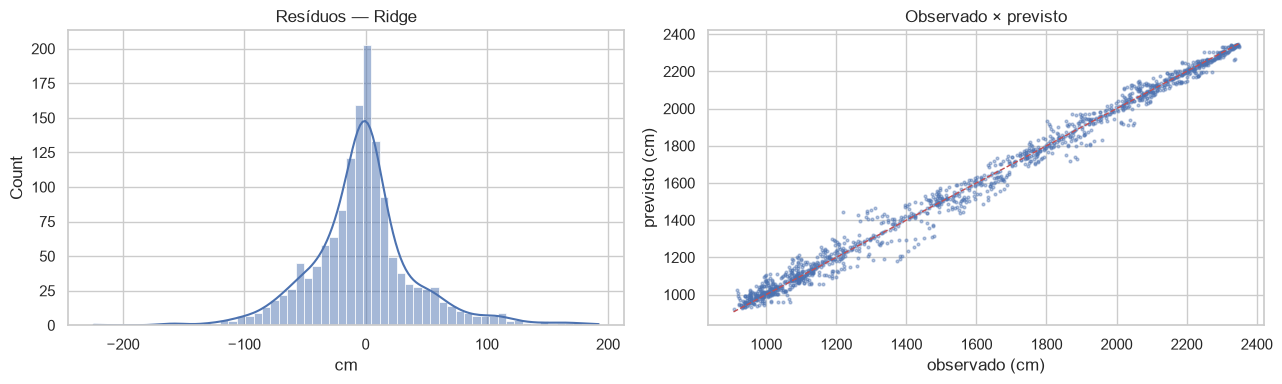

Ridge: viés médio = -2.1 cm, |erro| p95 = 96 cm


In [28]:
best = results.index[0]
res = cv["y"] - cv[best]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(res, bins=60, kde=True, ax=axes[0]); axes[0].set(title=f"Resíduos — {best}", xlabel="cm")
axes[1].scatter(cv["y"], cv[best], s=4, alpha=0.4); lim = [cv["y"].min(), cv["y"].max()]
axes[1].plot(lim, lim, "r--", lw=1); axes[1].set(xlabel="observado (cm)", ylabel="previsto (cm)", title="Observado × previsto")
plt.tight_layout(); plt.show()
print(f"{best}: viés médio = {res.mean():.1f} cm, |erro| p95 = {res.abs().quantile(.95):.0f} cm")

## 10. Leitura dos resultados e próximos passos

Como interpretar a tabela da seção 9:

1. **Persistência é o piso.** Em h = 1 dia é praticamente imbatível; a diferença entre modelos aparece em h ≥ 3.
2. **Persistência da anomalia** costuma ser o baseline mais forte — ela já incorpora o ciclo anual. Um modelo só é útil se bater esse baseline.
3. **PatchTST vs. LSTM/GRU:** compare RMSE e NSE nas seções 9 e 9.2. A literatura reporta PatchTST ≥ LSTM em vazão diária e ganho adicional com o ensemble; verifique se isso se repete aqui, e em qual regime (cheia/seca/transições).
4. **Modelos com lags (GradBoost)** são um comparativo barato e frequentemente competitivo em curto prazo.

Próximos passos sugeridos:
- Aumentar `MAX_STEPS` e fazer busca de hiperparâmetros (`input_size`, `hidden_size`, `patch_len`) com `AutoPatchTST`/`AutoLSTM` do NeuralForecast, usando a validação.
- Testar horizontes maiores (15 e 30 dias) — é onde Transformers e N-HiTS tendem a se destacar.
- Adicionar variáveis exógenas: cota de Santo Antônio (onde houver), chuva (CHIRPS/ANA) e as features de calendário nos modelos que aceitam `futr_exog_list`.
- Avaliar a incerteza com previsão probabilística (`loss=MQLoss()` no NeuralForecast).
- Repetir com várias sementes e reportar média ± desvio.

## 11. Múltiplos horizontes: 7, 15 e 30 dias

A literatura sugere que Transformers e N-HiTS se destacam em horizontes mais longos, enquanto persistência e modelos com lags dominam no curto prazo. Repetimos a comparação para **H = 7, 15 e 30 dias**, com:

- as mesmas origens de previsão a cada 7 dias no teste (janelas sobrepostas para H > 7);
- janela de entrada dos modelos de DL = `max(90, 4·H)` dias;
- um modelo direto por dia de antecedência nos modelos de ML (30 modelos para H = 30).

> Tempo: ~5 min por horizonte em CPU.

In [29]:
HORIZONS = [7, 15, 30]
STEP = 7
MODELS_H = ["Persistencia", "Climatologia", "PersistAnomalia", "ARIMA_anom", "Ridge", "GradBoost",
            "LSTM", "GRU", "DLinear", "NHITS", "PatchTST", "Ensemble_PatchTST_LSTM"]

def run_horizon(H_, max_steps=MAX_STEPS):
    input_size = max(90, 4 * H_)
    n_test = int((y.index >= TEST_START).sum())
    test_size = n_test - (n_test - H_) % STEP
    n_win = (test_size - H_) // STEP + 1
    t_end = y.index[n - test_size - 1]
    cuts = pd.DatetimeIndex([t_end + pd.Timedelta(days=STEP * k) for k in range(n_win)])
    cvh = make_cv(cuts, H_)

    # baselines
    cvh["Persistencia"] = y.loc[cvh["cutoff"]].values
    cvh["Climatologia"] = clim.loc[cvh["ds"]].values
    cvh["PersistAnomalia"] = clim.loc[cvh["ds"]].values + anom.loc[cvh["cutoff"]].values

    # ARIMA sobre a anomalia (mesmo ajuste da seção 6)
    cvh["ARIMA_anom"] = np.concatenate([arima_res.apply(anom.loc[:c].values).forecast(H_) for c in cuts]) \
                        + clim.loc[cvh["ds"]].values

    # ML direto, um modelo por dia de antecedência
    origins = y.index[N_LAGS + 1: y.index.get_loc(t_end) - H_ + 1]
    Xtr_base, Xte_base = build_features(origins), build_features(cuts)
    for name, make in ml_models.items():
        pred = np.zeros((len(cuts), H_))
        for h_ in range(1, H_ + 1):
            Xtr = add_target_clim(Xtr_base, h_)
            ytr = anom.loc[origins + pd.Timedelta(days=h_)].values
            Xte = add_target_clim(Xte_base, h_)
            pred[:, h_ - 1] = make().fit(Xtr, ytr).predict(Xte) + Xte["clim_target"].values
        cvh[name] = pred.reshape(-1)

    # deep learning
    cm = {**common, "h": H_, "input_size": input_size, "max_steps": max_steps}
    models = [LSTM(**rnn, **cm), GRU(**rnn, **cm), DLinear(learning_rate=1e-3, **cm), NHITS(learning_rate=1e-3, **cm),
              PatchTST(patch_len=16, stride=8, hidden_size=64, n_heads=4, encoder_layers=2, learning_rate=1e-4, **cm)]
    cvd = NeuralForecast(models=models, freq="D").cross_validation(
        df=nf_df, val_size=VAL_SIZE, test_size=test_size, step_size=STEP, n_windows=None)
    assert (cvd["cutoff"].unique() == cuts.values).all()
    cvh = cvh.merge(cvd[["ds", "cutoff"] + DL], on=["ds", "cutoff"], how="left")
    cvh["Ensemble_PatchTST_LSTM"] = (cvh["PatchTST"] + cvh["LSTM"]) / 2
    print(f"H={H_:2d}: {n_win} janelas, input_size={input_size}")
    return cvh

cv_by_h = {}
for H_ in HORIZONS:
    t0 = time.time()
    cv_by_h[H_] = run_horizon(H_)
    print(f"      concluído em {(time.time() - t0) / 60:.1f} min")

Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


GPU available: True (mps), used: False


... (74 outputs left out)

TPU available: False, using: 0 TPU cores


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


H=30: 205 janelas, input_size=120
      concluído em 4.6 min


### 11.1 RMSE e NSE por horizonte

In [30]:
summary = pd.concat({H_: evaluate(cvh, MODELS_H) for H_, cvh in cv_by_h.items()}, names=["H", "modelo"])
summary.to_csv("results_forecast_multi_h.csv")

rmse_h = summary["RMSE"].unstack("H").round(1).sort_values(HORIZONS[-1])
nse_h = summary["NSE"].unstack("H").round(3).loc[rmse_h.index]
# skill em relação à persistência: 1 - RMSE/RMSE_persistência (>0 = melhor que persistir)
skill_h = (1 - rmse_h / rmse_h.loc["Persistencia"]).round(2)

print("RMSE (cm) por horizonte:"); display(rmse_h.style.background_gradient(cmap="RdYlGn_r", axis=0))
print("Skill vs. persistência:"); display(skill_h.style.background_gradient(cmap="RdYlGn", axis=0, vmin=-0.3, vmax=0.5))
print("NSE:"); display(nse_h)

RMSE (cm) por horizonte:


H,7,15,30
modelo,,,
Ridge,43.800000,61.000000,83.600000
GradBoost,45.100000,66.200000,88.500000
ARIMA_anom,45.300000,63.800000,89.600000
PersistAnomalia,45.800000,66.500000,89.700000
PatchTST,48.200000,75.800000,106.900000
DLinear,48.300000,78.900000,117.300000
NHITS,56.500000,89.900000,129.700000
Climatologia,133.400000,132.800000,132.200000
Ensemble_PatchTST_LSTM,49.400000,81.800000,139.700000


Skill vs. persistência:


H,7,15,30
modelo,,,
Ridge,0.230000,0.360000,0.480000
GradBoost,0.210000,0.300000,0.450000
ARIMA_anom,0.210000,0.330000,0.440000
PersistAnomalia,0.200000,0.300000,0.440000
PatchTST,0.160000,0.200000,0.330000
DLinear,0.150000,0.170000,0.270000
NHITS,0.010000,0.050000,0.190000
Climatologia,-1.340000,-0.400000,0.170000
Ensemble_PatchTST_LSTM,0.130000,0.140000,0.130000


NSE:


H,7,15,30
modelo,,,
Ridge,0.991,0.983,0.969
GradBoost,0.991,0.980,0.965
ARIMA_anom,0.991,0.982,0.964
PersistAnomalia,0.990,0.980,0.964
PatchTST,0.989,0.974,0.949
DLinear,0.989,0.972,0.938
NHITS,0.986,0.963,0.924
Climatologia,0.919,0.920,0.921
Ensemble_PatchTST_LSTM,0.989,0.970,0.912


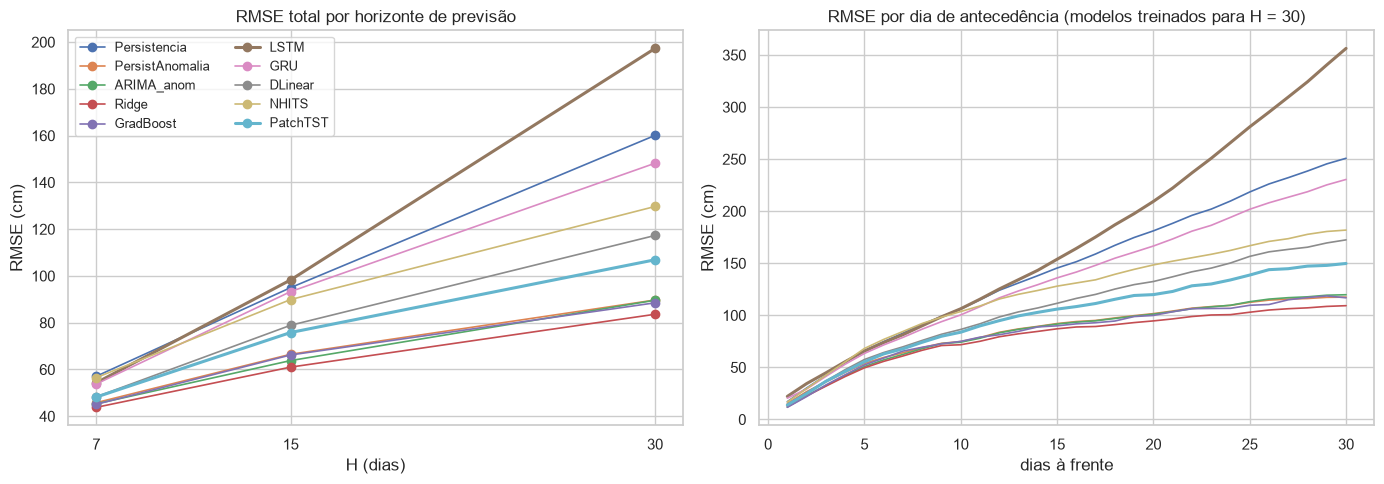

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show_h = ["Persistencia", "PersistAnomalia", "ARIMA_anom", "Ridge", "GradBoost", "LSTM", "GRU", "DLinear", "NHITS", "PatchTST"]
for m in show_h:
    axes[0].plot(HORIZONS, rmse_h.loc[m, HORIZONS], marker="o", label=m, lw=2.2 if m in ("PatchTST", "LSTM") else 1.2)
axes[0].set(title="RMSE total por horizonte de previsão", xlabel="H (dias)", ylabel="RMSE (cm)", xticks=HORIZONS)
axes[0].legend(ncol=2, fontsize=9)

# erro por dia de antecedência, do experimento H = 30
byh30 = evaluate_by_horizon(cv_by_h[30], show_h, "RMSE")
for m in show_h:
    axes[1].plot(byh30.index, byh30[m], label=m, lw=2.2 if m in ("PatchTST", "LSTM") else 1.2)
axes[1].set(title="RMSE por dia de antecedência (modelos treinados para H = 30)", xlabel="dias à frente", ylabel="RMSE (cm)")
plt.tight_layout(); plt.show()

### 11.2 Erro por regime hidrológico em H = 30

In [32]:
cv30 = cv_by_h[30].copy()
cv30["regime"] = pd.cut(cv30["ds"].dt.month, bins=[0, 2, 5, 8, 10, 12],
                        labels=["subida (jan-fev)", "cheia (mar-mai)", "vazante (jun-ago)", "seca (set-out)", "subida (nov-dez)"])
evaluate_by(cv30, ["Persistencia", "PersistAnomalia", "GradBoost", "LSTM", "GRU", "NHITS", "PatchTST", "Ensemble_PatchTST_LSTM"], "regime").round(1)

,Persistencia,PersistAnomalia,GradBoost,LSTM,GRU,NHITS,PatchTST,Ensemble_PatchTST_LSTM
regime,,,,,,,,
subida (jan-fev),182.1,112.9,101.1,198.1,178.3,171.2,133.9,160.1
cheia (mar-mai),131.2,65.0,62.7,129.8,112.5,111.0,97.8,109.2
vazante (jun-ago),178.8,80.7,74.6,231.3,122.7,109.7,94.4,149.5
seca (set-out),74.9,68.0,77.2,203.8,95.2,109.9,77.6,117.9
subida (nov-dez),207.1,125.1,131.6,218.8,227.9,156.6,133.5,164.6


### 11.3 Exemplo: previsões de 30 dias na cheia de 2022

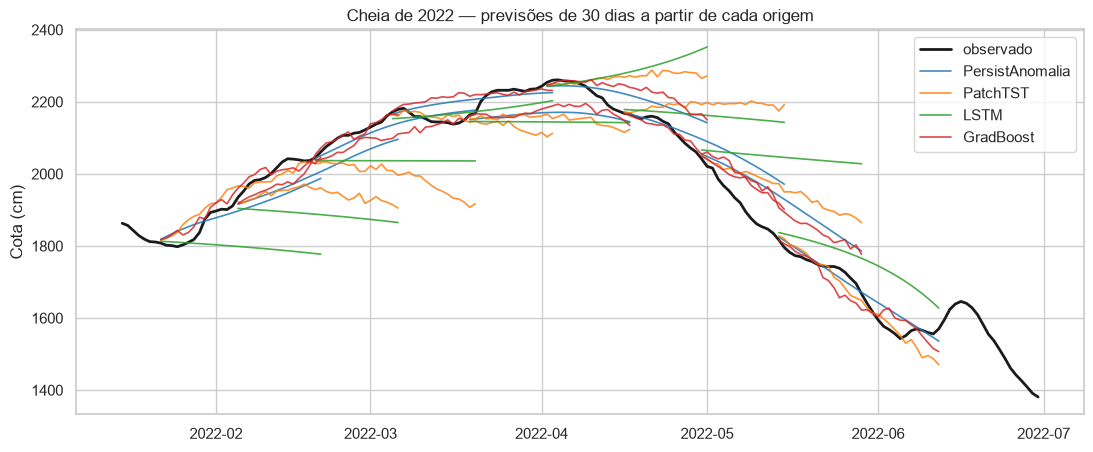

In [33]:
sub = cv_by_h[30]
sub = sub[(sub["cutoff"] >= "2022-01-15") & (sub["cutoff"] <= "2022-05-15")]
fig, ax = plt.subplots(figsize=(13, 5))
obs = y.loc["2022-01-15":"2022-06-30"]
ax.plot(obs.index, obs, "k-", lw=2, label="observado")
for i, m in enumerate(["PersistAnomalia", "PatchTST", "LSTM", "GradBoost"]):
    for j, (c, g) in enumerate(sub.groupby("cutoff")):
        if j % 2: continue                       # uma origem a cada 14 dias, para legibilidade
        ax.plot(g["ds"], g[m], lw=1.2, alpha=0.85, color=plt.cm.tab10(i), label=m if j == 0 else None)
ax.set(title="Cheia de 2022 — previsões de 30 dias a partir de cada origem", ylabel="Cota (cm)")
ax.legend(); plt.show()

### 11.4 Como ler

- **Skill vs. persistência** é a coluna que importa: mostra quanto cada modelo reduz o erro em relação a simplesmente repetir o último valor. Espera-se que cresça com H (persistir fica cada vez pior), e é em H = 30 que as arquiteturas de DL têm mais chance de se separar dos modelos de lags.
- O gráfico da direita (erro por dia de antecedência) mostra *onde* na janela de 30 dias cada modelo perde: um modelo pode ser bom nos primeiros dias e degradar rápido depois.
- Para o artigo, a comparação PatchTST × LSTM deve ser reportada **por horizonte**, não só para 7 dias.

## 12. Deep learning com informação sazonal + stacking

Na seção 11 os modelos que "conhecem" o ciclo anual (Ridge, ARIMA, persistência da anomalia) venceram todos os de deep learning, que eram univariados e viam só 90–120 dias de cota. Aqui damos ao DL a mesma informação, de duas formas:

1. **Alvo = anomalia** (cota − climatologia do dia do ano). O modelo aprende só o desvio; somamos a climatologia de volta na previsão. Vale para todos, inclusive PatchTST e DLinear, que não aceitam exógenas.
2. **Exógenas de calendário** (seno/cosseno do dia do ano) via `futr_exog_list`, nos modelos que aceitam: LSTM, GRU e N-HiTS.

E substituímos a média simples por um **stacking com pesos aprendidos** (mínimos quadrados não-negativos). Para não vazar informação do teste, os pesos são reestimados a cada origem usando apenas as janelas anteriores (*expanding window*); as primeiras `WARMUP` janelas servem só para calibrar.

In [34]:
from scipy.optimize import nnls

doy = y.index.dayofyear.values
nf_df_anom = pd.DataFrame({"unique_id": "humaita", "ds": y.index, "y": anom.values,
                           "sin": np.sin(2 * np.pi * doy / 365.25), "cos": np.cos(2 * np.pi * doy / 365.25)})
CAL = ["sin", "cos"]

def run_horizon_anom(H_, max_steps=MAX_STEPS):
    input_size = max(90, 4 * H_)
    n_test = int((y.index >= TEST_START).sum())
    test_size = n_test - (n_test - H_) % STEP
    n_win = (test_size - H_) // STEP + 1
    t_end = y.index[n - test_size - 1]
    cuts = pd.DatetimeIndex([t_end + pd.Timedelta(days=STEP * k) for k in range(n_win)])

    cm = {**common, "h": H_, "input_size": input_size, "max_steps": max_steps}
    models = [
        LSTM(**rnn, futr_exog_list=CAL, alias="LSTM_anom_cal", **cm),
        GRU(**rnn, futr_exog_list=CAL, alias="GRU_anom_cal", **cm),
        NHITS(learning_rate=1e-3, futr_exog_list=CAL, alias="NHITS_anom_cal", **cm),
        DLinear(learning_rate=1e-3, alias="DLinear_anom", **cm),
        PatchTST(patch_len=16, stride=8, hidden_size=64, n_heads=4, encoder_layers=2,
                 learning_rate=1e-4, alias="PatchTST_anom", **cm),
    ]
    names = [m.alias for m in models]
    cvd = NeuralForecast(models=models, freq="D").cross_validation(
        df=nf_df_anom, val_size=VAL_SIZE, test_size=test_size, step_size=STEP, n_windows=None)
    assert (cvd["cutoff"].unique() == cuts.values).all()
    cvd = cvd[["ds", "cutoff"] + names].copy()
    for m in names:                                   # anomalia -> cota
        cvd[m] = cvd[m].values + clim.loc[cvd["ds"]].values
    print(f"H={H_:2d}: {n_win} janelas, input_size={input_size}")
    return cvd, names

for H_ in HORIZONS:
    t0 = time.time()
    cvd, DL_ANOM = run_horizon_anom(H_)
    cv_by_h[H_] = cv_by_h[H_].drop(columns=[c for c in DL_ANOM if c in cv_by_h[H_]]).merge(cvd, on=["ds", "cutoff"], how="left")
    print(f"      concluído em {(time.time() - t0) / 60:.1f} min")

Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


GPU available: True (mps), used: False


... (73 outputs left out)

TPU available: False, using: 0 TPU cores


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


H=30: 205 janelas, input_size=120
      concluído em 2.3 min


### 12.1 Cota bruta × anomalia (+ calendário), por horizonte

In [35]:
pairs = [("LSTM", "LSTM_anom_cal"), ("GRU", "GRU_anom_cal"), ("NHITS", "NHITS_anom_cal"),
         ("DLinear", "DLinear_anom"), ("PatchTST", "PatchTST_anom")]
rows = {}
for raw, an in pairs:
    for H_, cvh in cv_by_h.items():
        rows[(raw, H_)] = {"cota bruta": rmse(cvh["y"].values, cvh[raw].values),
                           "anomalia": rmse(cvh["y"].values, cvh[an].values)}
cmp = pd.DataFrame(rows).T.rename_axis(["modelo", "H"])
cmp["ganho %"] = (100 * (1 - cmp["anomalia"] / cmp["cota bruta"])).round(1)
cmp.round(1).unstack("H").swaplevel(axis=1).sort_index(axis=1, level=0)

H              7                           15                          30  \
         anomalia cota bruta ganho % anomalia cota bruta ganho % anomalia   
modelo                                                                      
DLinear      43.7       48.3     9.5     64.6       78.9    18.1     86.5   
GRU          51.8       53.8     3.6     68.4       93.3    26.7    110.1   
LSTM         46.3       54.3    14.7     71.4       98.3    27.4     91.2   
NHITS        57.5       56.5    -1.9     90.8       89.9    -1.0    107.4   
PatchTST     42.6       48.2    11.7     63.8       75.8    15.7     89.4   

H                            
         cota bruta ganho %  
modelo                       
DLinear       117.3    26.3  
GRU           148.2    25.7  
LSTM          197.3    53.8  
NHITS         129.7    17.2  
PatchTST      106.9    16.4

In [36]:
ref = ["Persistencia", "PersistAnomalia", "Ridge", "GradBoost"]
summary2 = pd.concat({H_: evaluate(cvh, ref + DL_ANOM) for H_, cvh in cv_by_h.items()}, names=["H", "modelo"])
rmse2 = summary2["RMSE"].unstack("H").round(1).sort_values(30)
skill2 = (1 - rmse2 / rmse2.loc["Persistencia"]).round(2)
print("RMSE (cm):"); display(rmse2.style.background_gradient(cmap="RdYlGn_r", axis=0))
print("Skill vs. persistência:"); display(skill2.style.background_gradient(cmap="RdYlGn", axis=0, vmin=0, vmax=0.5))

RMSE (cm):


H,7,15,30
modelo,,,
Ridge,43.800000,61.000000,83.600000
DLinear_anom,43.700000,64.600000,86.500000
GradBoost,45.100000,66.200000,88.500000
PatchTST_anom,42.600000,63.800000,89.400000
PersistAnomalia,45.800000,66.500000,89.700000
LSTM_anom_cal,46.300000,71.400000,91.200000
NHITS_anom_cal,57.500000,90.800000,107.400000
GRU_anom_cal,51.800000,68.400000,110.100000
Persistencia,57.100000,95.000000,160.100000


Skill vs. persistência:


H,7,15,30
modelo,,,
Ridge,0.230000,0.360000,0.480000
DLinear_anom,0.230000,0.320000,0.460000
GradBoost,0.210000,0.300000,0.450000
PatchTST_anom,0.250000,0.330000,0.440000
PersistAnomalia,0.200000,0.300000,0.440000
LSTM_anom_cal,0.190000,0.250000,0.430000
NHITS_anom_cal,-0.010000,0.040000,0.330000
GRU_anom_cal,0.090000,0.280000,0.310000
Persistencia,0.000000,0.000000,0.000000


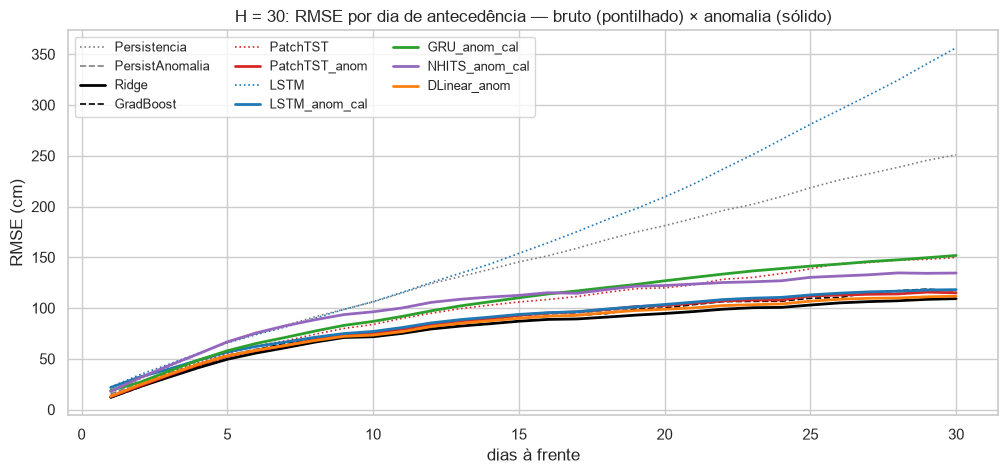

In [37]:
fig, ax = plt.subplots(figsize=(12, 5))
byh30 = evaluate_by_horizon(cv_by_h[30], ref + ["PatchTST", "LSTM"] + DL_ANOM, "RMSE")
styles = {"Persistencia": ("gray", ":"), "PersistAnomalia": ("gray", "--"), "Ridge": ("black", "-"), "GradBoost": ("black", "--"),
          "PatchTST": ("#d62728", ":"), "PatchTST_anom": ("#d62728", "-"), "LSTM": ("#1f77b4", ":"), "LSTM_anom_cal": ("#1f77b4", "-"),
          "GRU_anom_cal": ("#2ca02c", "-"), "NHITS_anom_cal": ("#9467bd", "-"), "DLinear_anom": ("#ff7f0e", "-")}
for m, (c, ls) in styles.items():
    ax.plot(byh30.index, byh30[m], color=c, ls=ls, lw=2 if "anom" in m or m == "Ridge" else 1.2, label=m)
ax.set(title="H = 30: RMSE por dia de antecedência — bruto (pontilhado) × anomalia (sólido)", xlabel="dias à frente", ylabel="RMSE (cm)")
ax.legend(ncol=3, fontsize=9); plt.show()

### 12.2 Stacking com pesos aprendidos (NNLS, janela expansiva)

In [38]:
WARMUP = 26   # ~6 meses de janelas só para calibrar os pesos iniciais

def stack_nnls(cvh, members, warmup=WARMUP):
    # a cada origem, pesos NNLS ajustados sobre a anomalia usando só as janelas anteriores
    cvh = cvh.sort_values(["cutoff", "ds"]).reset_index(drop=True)
    c_ = clim.loc[cvh["ds"]].values
    P = cvh[members].values - c_[:, None]
    t = cvh["y"].values - c_
    cuts_ = cvh["cutoff"].unique()
    out = np.full(len(cvh), np.nan); W = []
    for k in range(warmup, len(cuts_)):
        past = cvh["cutoff"] < cuts_[k]
        w, _ = nnls(P[past.values], t[past.values])
        W.append(w)
        cur = (cvh["cutoff"] == cuts_[k]).values
        out[cur] = P[cur] @ w + c_[cur]
    return pd.Series(out, index=cvh.index), pd.DataFrame(W, columns=members, index=cuts_[warmup:])

STACKS = {
    "Stack_PatchTST_LSTM": ["PatchTST_anom", "LSTM_anom_cal"],
    "Stack_DL": DL_ANOM,
    "Stack_DL+ML": DL_ANOM + ["Ridge", "GradBoost", "PersistAnomalia"],
}
weights = {}
for H_, cvh in cv_by_h.items():
    cvh = cvh.sort_values(["cutoff", "ds"]).reset_index(drop=True)
    for name, members in STACKS.items():
        cvh[name], weights[(H_, name)] = stack_nnls(cvh, members)
    cvh["Media_PatchTST_LSTM"] = (cvh["PatchTST_anom"] + cvh["LSTM_anom_cal"]) / 2
    cv_by_h[H_] = cvh

# avaliação só nas janelas após o warm-up (onde o stacking existe), para todos os modelos
STACK_TAB = ["Persistencia", "PersistAnomalia", "Ridge", "GradBoost", "PatchTST_anom", "LSTM_anom_cal",
             "Media_PatchTST_LSTM"] + list(STACKS)
summary3 = pd.concat({H_: evaluate(cvh[cvh["Stack_DL"].notna()], STACK_TAB) for H_, cvh in cv_by_h.items()}, names=["H", "modelo"])
summary3.to_csv("results_forecast_multi_h_anom_stacking.csv")
rmse3 = summary3["RMSE"].unstack("H").round(1).sort_values(30)
print(f"RMSE (cm) nas janelas após o warm-up ({WARMUP} janelas):")
rmse3.style.background_gradient(cmap="RdYlGn_r", axis=0)

RMSE (cm) nas janelas após o warm-up (26 janelas):


H,7,15,30
modelo,,,
Stack_DL+ML,43.000000,62.400000,84.200000
Stack_DL,42.900000,63.700000,84.800000
Ridge,45.100000,62.000000,85.100000
Stack_PatchTST_LSTM,42.900000,63.400000,85.700000
Media_PatchTST_LSTM,44.800000,66.400000,89.200000
GradBoost,46.300000,67.300000,89.600000
PersistAnomalia,46.300000,67.100000,90.400000
PatchTST_anom,43.600000,64.500000,90.900000
LSTM_anom_cal,47.600000,72.400000,91.500000


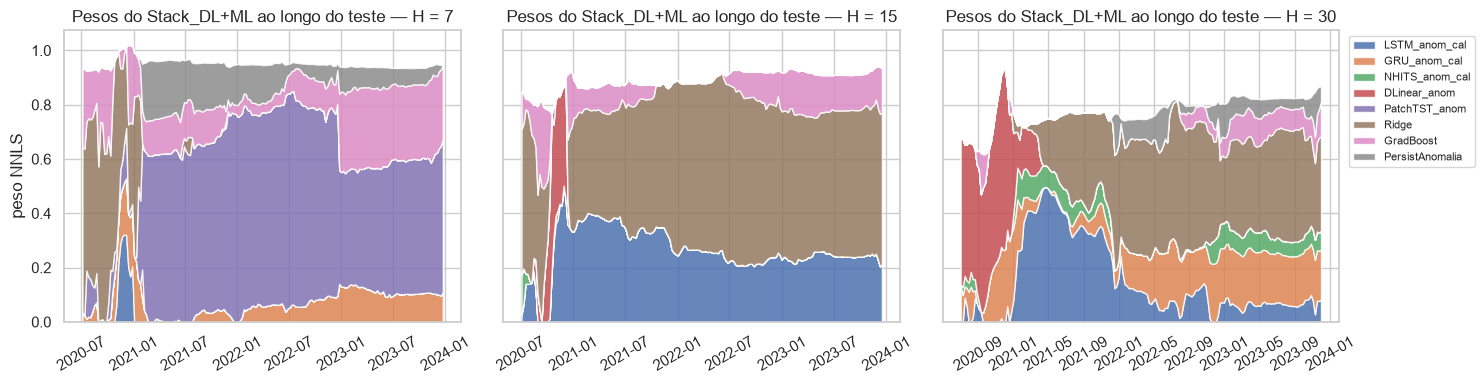

Pesos finais (última origem), H = 30:


LSTM_anom_cal      0.08
GRU_anom_cal       0.18
NHITS_anom_cal     0.07
DLinear_anom       0.00
PatchTST_anom      0.00
Ridge              0.35
GradBoost          0.13
PersistAnomalia    0.06
Name: 2023-12-01 00:00:00, dtype: float64

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, H_ in zip(axes, HORIZONS):
    w = weights[(H_, "Stack_DL+ML")]
    ax.stackplot(w.index, w.values.T, labels=w.columns, alpha=0.85)
    ax.set(title=f"Pesos do Stack_DL+ML ao longo do teste — H = {H_}", ylabel="peso NNLS" if H_ == HORIZONS[0] else None)
    ax.tick_params(axis="x", rotation=30)
axes[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print("Pesos finais (última origem), H = 30:")
weights[(30, "Stack_DL+ML")].iloc[-1].round(2)

### 12.3 Como ler

- **Bruto × anomalia:** a tabela 12.1 mostra o ganho de cada arquitetura ao receber a sazonalidade. Se o ganho for grande e o `*_anom` se aproximar do Ridge, a conclusão é que a arquitetura em si importa menos que a representação do alvo.
- **PatchTST × LSTM, agora em igualdade de informação:** compare `PatchTST_anom` e `LSTM_anom_cal` por horizonte — esta é a comparação que deve ir para o artigo.
- **Stacking:** `Stack_PatchTST_LSTM` responde se a combinação dos dois vale a pena quando os pesos são aprendidos; `Stack_DL+ML` é o teto prático com os modelos disponíveis. O gráfico de pesos mostra em quem o stacking confia e se isso muda entre cheia e seca.

## 13. Rigor estatístico

As seções anteriores comparam modelos por um único treino e uma única configuração. Antes de levar qualquer ranking para o artigo, é preciso responder a três perguntas:

1. **As diferenças sobrevivem à troca da semente aleatória?** (13.2)
2. **As diferenças são estatisticamente significativas?** (13.3, teste de Diebold-Mariano)
3. **O ranking muda com uma busca de hiperparâmetros honesta, feita só na validação?** (13.4)

E uma quarta, sobre a qualidade dos dados: **o preenchimento das lacunas e os dias "estimados" pela ANA afetam as conclusões?** (13.1)

Todos os experimentos desta seção usam **H = 30**, o horizonte em que os modelos mais se separam.

### 13.1 Sensibilidade aos dados imputados e estimados

Três fontes de incerteza nos dados:

- os **21 dias interpolados** por nós (abr/mai 2014), que ficam no período de **treino**;
- os **919 dias marcados como "estimado" (status 2)** pela própria ANA, espalhados pela série;
- a **escolha do método de interpolação**.

Verificamos o efeito de cada uma.

In [40]:
H_S = 30
cv_s = cv_by_h[H_S]

status_all = humaita_raw["status"].reindex(idx)
est = (status_all == 2)                       # estimado pela ANA
print(f"Dias estimados pela ANA em 1991-2023: {int(est.sum())}")
print(f"  no período de teste: {int(est.loc[TEST_START:].sum())}"
      f"  (por ano: {est.loc[TEST_START:].groupby(est.loc[TEST_START:].index.year).sum().to_dict()})")
print(f"Dias interpolados por nós: {int(imputed.sum())} — todos em {sorted(set(y.index[imputed].year))}, "
      f"ou seja, {'no treino' if not imputed.loc[TEST_START:].any() else 'ALGUNS NO TESTE'}")

MODELS_SENS = ["Persistencia", "PersistAnomalia", "Ridge", "GradBoost"] + DL_ANOM
keep_target = ~cv_s["ds"].map(est).fillna(False).to_numpy()      # alvo não é dia estimado
keep_origin = ~cv_s["cutoff"].map(est).fillna(False).to_numpy()   # origem não é dia estimado

sens = pd.concat({
    "todas as janelas": evaluate(cv_s, MODELS_SENS)["RMSE"],
    "sem alvos estimados": evaluate(cv_s[keep_target], MODELS_SENS)["RMSE"],
    "sem origens estimadas": evaluate(cv_s[keep_origin], MODELS_SENS)["RMSE"],
}, axis=1).round(1)
sens["Δ máx (cm)"] = (sens.max(axis=1) - sens.min(axis=1)).round(1)
print(f"\nRMSE (cm) em H = {H_S}, alvos excluídos: {int((~keep_target).sum())} de {len(cv_s)} linhas")
sens.sort_values("todas as janelas")

Dias estimados pela ANA em 1991-2023: 919
  no período de teste: 40  (por ano: {2020: 7, 2021: 0, 2022: 0, 2023: 33})
Dias interpolados por nós: 21 — todos em [2014], ou seja, no treino

RMSE (cm) em H = 30, alvos excluídos: 172 de 6150 linhas


,todas as janelas,sem alvos estimados,sem origens estimadas,Δ máx (cm)
Ridge,83.6,82.9,81.6,2.0
DLinear_anom,86.5,86.4,84.8,1.7
GradBoost,88.5,87.6,87.3,1.2
PatchTST_anom,89.4,89.2,87.8,1.6
PersistAnomalia,89.7,90.2,88.3,1.9
LSTM_anom_cal,91.2,92.0,90.6,1.4
NHITS_anom_cal,107.4,108.6,106.4,2.2
GRU_anom_cal,110.1,111.3,110.6,1.2
Persistencia,160.1,162.3,159.8,2.5


Agora o efeito do **método de interpolação**, usando os modelos rápidos (treino em segundos) para poder repetir o pipeline inteiro por método:

In [41]:
def ml_direct_from_series(y_s, cuts, H_, factory, n_lags=N_LAGS):
    # versão autocontida do ML direto da seção 7: features e alvo derivados de `y_s`
    tr = y_s.loc[:cuts[0]]
    cd = tr.groupby(tr.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    _c = pd.concat([cd.iloc[-15:], cd, cd.iloc[:15]]).rolling(15, center=True).mean()
    cd = _c.iloc[15:-15]; cd.index = range(1, 367)
    cl = pd.Series(cd.loc[y_s.index.dayofyear].to_numpy(), index=y_s.index)
    an = y_s - cl

    def feats(t_index):
        pos = y_s.index.get_indexer(t_index)
        Y, A = y_s.to_numpy(), an.to_numpy()
        F = {f"lag{k}": Y[pos - k] for k in range(n_lags)}
        F.update(anom0=A[pos], d1=Y[pos] - Y[pos - 1], d7=Y[pos] - Y[pos - 7], d30=Y[pos] - Y[pos - 30])
        d_ = t_index.dayofyear.to_numpy()
        F.update(sin=np.sin(2 * np.pi * d_ / 365.25), cos=np.cos(2 * np.pi * d_ / 365.25))
        return pd.DataFrame(F, index=t_index)

    origins = y_s.index[n_lags + 1: y_s.index.get_loc(cuts[0]) - H_ + 1]
    Xtr_b, Xte_b = feats(origins), feats(cuts)
    pred = np.zeros((len(cuts), H_))
    for h_ in range(1, H_ + 1):
        ct_tr = cd.loc[(Xtr_b.index + pd.Timedelta(days=h_)).dayofyear].to_numpy()
        ct_te = cd.loc[(Xte_b.index + pd.Timedelta(days=h_)).dayofyear].to_numpy()
        Xtr = Xtr_b.assign(clim_target=ct_tr); Xte = Xte_b.assign(clim_target=ct_te)
        ytr = an.loc[origins + pd.Timedelta(days=h_)].to_numpy()
        pred[:, h_ - 1] = factory().fit(Xtr, ytr).predict(Xte) + ct_te
    return pred.reshape(-1)

cuts_s = pd.DatetimeIndex(cv_s["cutoff"].unique())
fill_rows = {}
for method in ["linear", "pchip", "akima", "cubic"]:
    y_alt = fill(y_raw, method)
    fill_rows[method] = {name: rmse(cv_s["y"].to_numpy(), ml_direct_from_series(y_alt, cuts_s, H_S, mk))
                         for name, mk in ml_models.items()}
fill_tab = pd.DataFrame(fill_rows).T.round(2)
fill_tab["Δ vs. linear (cm)"] = (fill_tab - fill_tab.loc["linear"]).abs().max(axis=1).round(2)
print(f"RMSE (cm) em H = {H_S} conforme o método de preenchimento das lacunas de 2014:")
fill_tab

RMSE (cm) em H = 30 conforme o método de preenchimento das lacunas de 2014:


,Ridge,GradBoost,Δ vs. linear (cm)
linear,83.68,88.70,0.00
pchip,83.69,88.31,0.39
akima,83.69,88.60,0.10
cubic,83.69,88.47,0.23


### 13.2 Reprodutibilidade: múltiplas sementes

In [42]:
SEEDS = [42, 7, 13, 21, 99]

def run_seed(H_, seed, max_steps=MAX_STEPS):
    input_size = max(90, 4 * H_)
    n_test = int((y.index >= TEST_START).sum())
    test_size = n_test - (n_test - H_) % STEP
    cm = {**common, "h": H_, "input_size": input_size, "max_steps": max_steps, "random_seed": seed}
    models = [
        LSTM(**rnn, futr_exog_list=CAL, alias="LSTM_anom_cal", **cm),
        GRU(**rnn, futr_exog_list=CAL, alias="GRU_anom_cal", **cm),
        NHITS(learning_rate=1e-3, futr_exog_list=CAL, alias="NHITS_anom_cal", **cm),
        DLinear(learning_rate=1e-3, alias="DLinear_anom", **cm),
        PatchTST(patch_len=16, stride=8, hidden_size=64, n_heads=4, encoder_layers=2,
                 learning_rate=1e-4, alias="PatchTST_anom", **cm),
    ]
    names = [m.alias for m in models]
    cvd = NeuralForecast(models=models, freq="D").cross_validation(
        df=nf_df_anom, val_size=VAL_SIZE, test_size=test_size, step_size=STEP, n_windows=None)
    cvd = cvd.sort_values(["cutoff", "ds"]).reset_index(drop=True)
    for m in names:
        cvd[m] = cvd[m].to_numpy() + clim.loc[cvd["ds"]].to_numpy()
    return cvd[["ds", "cutoff"] + names], names

seed_runs = {}
for sd in SEEDS:
    t0 = time.time()
    seed_runs[sd], DL_ANOM_NAMES = run_seed(H_S, sd)
    r_ = {m: rmse(cv_s["y"].to_numpy(), seed_runs[sd][m].to_numpy()) for m in DL_ANOM_NAMES}
    print(f"semente {sd:3d} ({(time.time()-t0)/60:4.1f} min): " + "  ".join(f"{k}={v:.0f}" for k, v in r_.items()))

Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


Seed set to 42


GPU available: True (mps), used: False


... (121 outputs left out)

TPU available: False, using: 0 TPU cores


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


semente  99 ( 3.0 min): LSTM_anom_cal=98  GRU_anom_cal=116  NHITS_anom_cal=114  DLinear_anom=87  PatchTST_anom=89


In [43]:
# RMSE de cada modelo em cada semente
seed_rmse = pd.DataFrame({sd: {m: rmse(cv_s["y"].to_numpy(), run[m].to_numpy()) for m in DL_ANOM_NAMES}
                          for sd, run in seed_runs.items()})
tab = pd.DataFrame({
    "média": seed_rmse.mean(axis=1), "desvio": seed_rmse.std(axis=1),
    "mín": seed_rmse.min(axis=1), "máx": seed_rmse.max(axis=1),
    "amplitude": seed_rmse.max(axis=1) - seed_rmse.min(axis=1),
}).round(1)
# referências sem semente (determinísticas)
det = {m: rmse(cv_s["y"].to_numpy(), cv_s[m].to_numpy()) for m in ["Ridge", "GradBoost", "PersistAnomalia", "Persistencia"]}
tab = pd.concat([tab, pd.DataFrame({"média": det}).round(1)]).sort_values("média")
print(f"RMSE (cm) em H = {H_S} sobre {len(SEEDS)} sementes (determinísticos sem desvio):")
display(tab)

print("\nRanking por semente (1 = melhor):")
display(seed_rmse.rank().astype(int))

RMSE (cm) em H = 30 sobre 5 sementes (determinísticos sem desvio):


,média,desvio,mín,máx,amplitude
Ridge,83.6,NaN,NaN,NaN,NaN
DLinear_anom,86.5,0.3,86.1,86.8,0.7
PatchTST_anom,88.4,0.9,86.9,89.4,2.4
GradBoost,88.5,NaN,NaN,NaN,NaN
PersistAnomalia,89.7,NaN,NaN,NaN,NaN
LSTM_anom_cal,93.6,3.6,90.1,98.3,8.2
NHITS_anom_cal,109.1,3.4,105.2,114.3,9.1
GRU_anom_cal,111.1,6.3,102.3,118.0,15.7
Persistencia,160.1,NaN,NaN,NaN,NaN



Ranking por semente (1 = melhor):


,42,7,13,21,99
LSTM_anom_cal,3,3,3,3,3
GRU_anom_cal,5,4,4,5,5
NHITS_anom_cal,4,5,5,4,4
DLinear_anom,1,1,1,1,1
PatchTST_anom,2,2,2,2,2


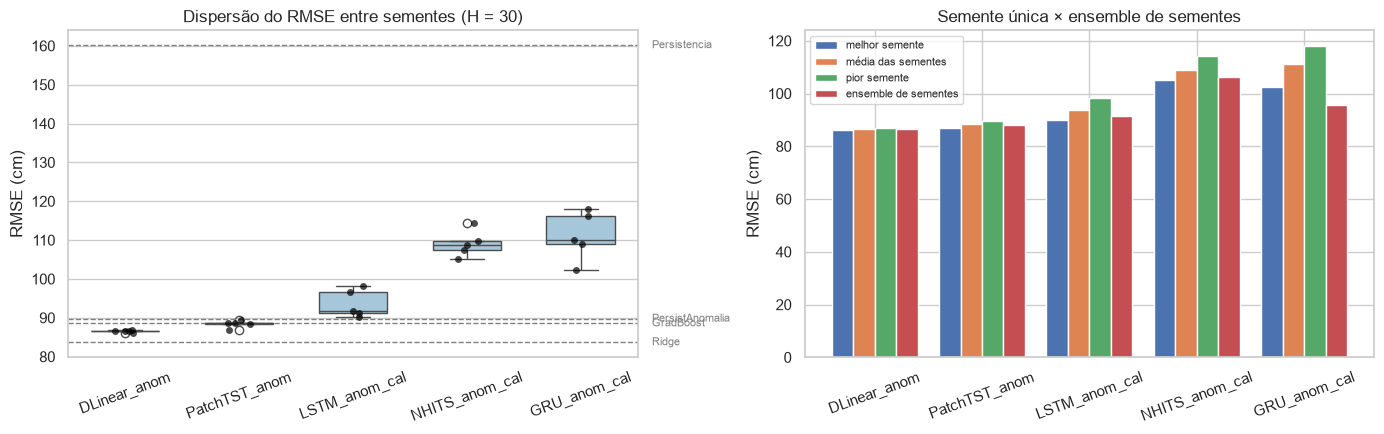

,melhor semente,média das sementes,pior semente,ensemble de sementes
DLinear_anom,86.1,86.5,86.8,86.4
PatchTST_anom,86.9,88.4,89.4,88.0
LSTM_anom_cal,90.1,93.6,98.3,91.3
NHITS_anom_cal,105.2,109.1,114.3,106.4
GRU_anom_cal,102.3,111.1,118.0,95.8


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = seed_rmse.mean(axis=1).sort_values().index
sns.boxplot(data=seed_rmse.T[order], ax=axes[0], color="#9ecae1", width=0.6)
sns.stripplot(data=seed_rmse.T[order], ax=axes[0], color="black", size=5, alpha=0.7)
for name, v in det.items():
    axes[0].axhline(v, ls="--", lw=1, color="gray")
    axes[0].text(len(order) - 0.4, v, f" {name}", va="center", fontsize=8, color="gray")
axes[0].set(title=f"Dispersão do RMSE entre sementes (H = {H_S})", ylabel="RMSE (cm)")
axes[0].tick_params(axis="x", rotation=20)

# média das sementes (ensemble) vs. semente única
mean_pred = {m: np.mean([run[m].to_numpy() for run in seed_runs.values()], axis=0) for m in DL_ANOM_NAMES}
comp = pd.DataFrame({
    "melhor semente": seed_rmse.min(axis=1), "média das sementes": seed_rmse.mean(axis=1),
    "pior semente": seed_rmse.max(axis=1),
    "ensemble de sementes": {m: rmse(cv_s["y"].to_numpy(), p) for m, p in mean_pred.items()},
}).round(1).loc[order]
comp.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set(title="Semente única × ensemble de sementes", ylabel="RMSE (cm)"); axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# guarda o ensemble de sementes para o teste de significância
for m, p in mean_pred.items():
    cv_s[m + "_seedmean"] = p
comp

### 13.3 Teste de Diebold-Mariano

Compara dois modelos pela diferença de perda quadrática. Duas correções necessárias aqui:

- as janelas de teste **se sobrepõem** (origens a cada 7 dias, horizonte de 30), então a diferença de perda é autocorrelacionada — usamos variância **HAC de Newey-West** com `overlap = ⌈h/STEP⌉` defasagens;
- amostra finita e previsão multi-passo pedem a correção de **Harvey-Leybourne-Newbold**, com a estatística comparada à distribuição *t*.

H₀: os dois modelos têm a mesma acurácia. p < 0,05 indica diferença significativa.

In [45]:
from scipy import stats

def dm_test(cv_, m1, m2, h=None, step=STEP, power=2):
    d = cv_ if h is None else cv_[(cv_["ds"] - cv_["cutoff"]).dt.days == h]
    e1 = np.abs(d["y"].to_numpy() - d[m1].to_numpy()) ** power
    e2 = np.abs(d["y"].to_numpy() - d[m2].to_numpy()) ** power
    diff = e1 - e2
    n = len(diff)
    overlap = max(1, int(np.ceil((h if h else (cv_["ds"] - cv_["cutoff"]).dt.days.max()) / step)))
    dc = diff - diff.mean()
    gamma = [dc @ dc / n] + [dc[k:] @ dc[:-k] / n for k in range(1, overlap)]
    var = max(gamma[0] + 2 * sum((1 - k / overlap) * gamma[k] for k in range(1, overlap)), 1e-12)
    dm = diff.mean() / np.sqrt(var / n)
    hln = np.sqrt(max((n + 1 - 2 * overlap + overlap * (overlap - 1) / n) / n, 1e-9))
    dm *= hln
    return dm, 2 * (1 - stats.t.cdf(abs(dm), df=n - 1))

DM_MODELS = ["Persistencia", "PersistAnomalia", "Ridge", "GradBoost"] + [m + "_seedmean" for m in DL_ANOM_NAMES]

def dm_matrix(cv_, models, h):
    P = pd.DataFrame(np.nan, index=models, columns=models)
    for i, a in enumerate(models):
        for b in models[i + 1:]:
            _, p = dm_test(cv_, a, b, h=h)
            P.loc[a, b] = P.loc[b, a] = p
    return P

for h_ in (7, 30):
    P = dm_matrix(cv_s, DM_MODELS, h_)
    print(f"\np-valores de Diebold-Mariano, antecedência de {h_} dias "
          f"(células < 0,05 = diferença significativa):")
    display(P.round(3).style.background_gradient(cmap="RdYlGn_r", vmin=0, vmax=0.2).format("{:.3f}", na_rep="—"))


p-valores de Diebold-Mariano, antecedência de 7 dias (células < 0,05 = diferença significativa):


,Persistencia,PersistAnomalia,Ridge,GradBoost,LSTM_anom_cal_seedmean,GRU_anom_cal_seedmean,NHITS_anom_cal_seedmean,DLinear_anom_seedmean,PatchTST_anom_seedmean
Persistencia,—,0.000,0.000,0.006,0.000,0.000,0.796,0.000,0.000
PersistAnomalia,0.000,—,0.290,0.695,0.127,0.732,0.000,0.212,0.422
Ridge,0.000,0.290,—,0.121,0.149,0.128,0.000,0.489,0.331
GradBoost,0.006,0.695,0.121,—,0.976,0.794,0.001,0.383,0.442
LSTM_anom_cal_seedmean,0.000,0.127,0.149,0.976,—,0.579,0.000,0.071,0.114
GRU_anom_cal_seedmean,0.000,0.732,0.128,0.794,0.579,—,0.000,0.126,0.157
NHITS_anom_cal_seedmean,0.796,0.000,0.000,0.001,0.000,0.000,—,0.000,0.000
DLinear_anom_seedmean,0.000,0.212,0.489,0.383,0.071,0.126,0.000,—,0.495
PatchTST_anom_seedmean,0.000,0.422,0.331,0.442,0.114,0.157,0.000,0.495,—



p-valores de Diebold-Mariano, antecedência de 30 dias (células < 0,05 = diferença significativa):


,Persistencia,PersistAnomalia,Ridge,GradBoost,LSTM_anom_cal_seedmean,GRU_anom_cal_seedmean,NHITS_anom_cal_seedmean,DLinear_anom_seedmean,PatchTST_anom_seedmean
Persistencia,—,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PersistAnomalia,0.000,—,0.096,0.927,0.752,0.154,0.163,0.115,0.278
Ridge,0.000,0.096,—,0.096,0.254,0.049,0.022,0.234,0.134
GradBoost,0.000,0.927,0.096,—,0.790,0.170,0.188,0.374,0.625
LSTM_anom_cal_seedmean,0.000,0.752,0.254,0.790,—,0.143,0.410,0.345,0.476
GRU_anom_cal_seedmean,0.000,0.154,0.049,0.170,0.143,—,0.585,0.063,0.091
NHITS_anom_cal_seedmean,0.000,0.163,0.022,0.188,0.410,0.585,—,0.035,0.062
DLinear_anom_seedmean,0.000,0.115,0.234,0.374,0.345,0.063,0.035,—,0.233
PatchTST_anom_seedmean,0.000,0.278,0.134,0.625,0.476,0.091,0.062,0.233,—


In [46]:
# comparações que interessam ao artigo, por antecedência
PAIRS = [("PatchTST_anom_seedmean", "LSTM_anom_cal_seedmean"),
         ("PatchTST_anom_seedmean", "GRU_anom_cal_seedmean"),
         ("PatchTST_anom_seedmean", "Ridge"),
         ("Ridge", "PersistAnomalia"),
         ("PatchTST_anom_seedmean", "PersistAnomalia"),
         ("NHITS_anom_cal_seedmean", "PatchTST_anom_seedmean")]
rows = []
for a, b in PAIRS:
    for h_ in (1, 7, 15, 30):
        dm, p = dm_test(cv_s, a, b, h=h_)
        ra, rb = rmse(cv_s["y"].to_numpy(), cv_s[a].to_numpy()), rmse(cv_s["y"].to_numpy(), cv_s[b].to_numpy())
        rows.append({"modelo A": a.replace("_seedmean", ""), "modelo B": b.replace("_seedmean", ""), "h": h_,
                     "DM": round(dm, 2), "p": round(p, 4),
                     "melhor": (a if dm < 0 else b).replace("_seedmean", "") if p < 0.05 else "empate"})
pd.DataFrame(rows).pivot(index=["modelo A", "modelo B"], columns="h", values=["DM", "p", "melhor"]).swaplevel(axis=1).sort_index(axis=1)

h                                 1                            7   \
                                  DM         melhor       p    DM   
modelo A       modelo B                                             
NHITS_anom_cal PatchTST_anom    5.37  PatchTST_anom     0.0  4.84   
PatchTST_anom  GRU_anom_cal    -4.16  PatchTST_anom     0.0 -1.42   
               LSTM_anom_cal   -5.42  PatchTST_anom     0.0 -1.59   
               PersistAnomalia -3.82  PatchTST_anom  0.0002  -0.8   
               Ridge            1.07         empate  0.2868  0.97   
Ridge          PersistAnomalia -3.02          Ridge  0.0029 -1.06   

h                                                        15                 \
                                       melhor       p    DM         melhor   
modelo A       modelo B                                                      
NHITS_anom_cal PatchTST_anom    PatchTST_anom     0.0  3.32  PatchTST_anom   
PatchTST_anom  GRU_anom_cal            empate  0.1566 -0.76         empate   
               LSTM_anom_cal           empate  0.1138 -0.64         empate   
               PersistAnomalia         empate  0.4223 -0.33         empate   
               Ridge                   empate  0.3313  2.53          Ridge   
Ridge          PersistAnomalia         empate  0.2898  -1.8         empate   

h                                         30                  
                                     p    DM  melhor       p  
modelo A       modelo B                                       
NHITS_anom_cal PatchTST_anom    0.0011  1.88  empate  0.0617  
PatchTST_anom  GRU_anom_cal     0.4502  -1.7  empate  0.0913  
               LSTM_anom_cal     0.523 -0.71  empate  0.4756  
               PersistAnomalia  0.7454 -1.09  empate  0.2783  
               Ridge            0.0123   1.5  empate  0.1344  
Ridge          PersistAnomalia  0.0728 -1.67  empate   0.096

### 13.4 Busca de hiperparâmetros (só na validação)

`AutoPatchTST` e `AutoLSTM` do NeuralForecast, com backend **optuna**. A busca minimiza a perda na **validação (2016–2019)**; o teste (2020–2023) nunca é consultado. Ao final, a melhor configuração é reavaliada no teste e comparada com a configuração usada nas seções 8–12.

> Orçamento reduzido (`AUTO_SAMPLES` amostras, `AUTO_MAX_STEPS` passos) para o notebook rodar em tempo razoável. Para o artigo, aumente os dois.

In [47]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from neuralforecast.auto import AutoPatchTST, AutoLSTM

AUTO_SAMPLES, AUTO_MAX_STEPS = 8, 300
_fixed = dict(val_check_steps=25, early_stop_patience_steps=4, scaler_type="standard", batch_size=64,
              random_seed=SEED, enable_progress_bar=False, enable_model_summary=False, logger=False,
              accelerator="cpu", max_steps=AUTO_MAX_STEPS)

def cfg_patchtst(trial):
    return dict(input_size=trial.suggest_categorical("input_size", [90, 120, 180, 365]),
                patch_len=trial.suggest_categorical("patch_len", [8, 16, 24]),
                stride=trial.suggest_categorical("stride", [4, 8, 16]),
                hidden_size=trial.suggest_categorical("hidden_size", [64, 128, 256]),
                n_heads=trial.suggest_categorical("n_heads", [4, 8]),
                encoder_layers=trial.suggest_int("encoder_layers", 1, 3),
                learning_rate=trial.suggest_float("learning_rate", 1e-5, 1e-3, log=True), **_fixed)

def cfg_lstm(trial):
    hs = trial.suggest_categorical("hidden_size", [64, 128, 256])
    return dict(input_size=trial.suggest_categorical("input_size", [30, 90, 120, 180]),
                encoder_hidden_size=hs, decoder_hidden_size=hs,
                encoder_n_layers=trial.suggest_int("encoder_n_layers", 1, 3),
                recurrent=trial.suggest_categorical("recurrent", [True, False]),
                learning_rate=trial.suggest_float("learning_rate", 1e-4, 5e-3, log=True),
                futr_exog_list=CAL, **_fixed)

auto_models = [AutoPatchTST(h=H_S, config=cfg_patchtst, backend="optuna", num_samples=AUTO_SAMPLES,
                            verbose=False, alias="AutoPatchTST"),
               AutoLSTM(h=H_S, config=cfg_lstm, backend="optuna", num_samples=AUTO_SAMPLES,
                        verbose=False, alias="AutoLSTM")]
t0 = time.time()
nf_auto = NeuralForecast(models=auto_models, freq="D")
nf_auto.fit(df=nf_df_anom, val_size=VAL_SIZE)
print(f"busca concluída em {(time.time() - t0) / 60:.1f} min")

trials = {}
for m in nf_auto.models:
    st = m.results
    trials[m.alias] = (pd.DataFrame([{**t.params, "val_loss": t.value} for t in st.trials])
                         .sort_values("val_loss").reset_index(drop=True))
    print(f"\n{m.alias} — melhor perda de validação: {st.best_trial.value:.2f}")
    display(trials[m.alias].round(5))

Seed set to 42


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


`Trainer.fit` stopped: `max_steps=300` reached.


Seed set to 42


GPU available: True (mps), used: False


... (62 outputs left out)

busca concluída em 21.0 min

AutoPatchTST — melhor perda de validação: 62.66


,input_size,patch_len,stride,hidden_size,n_heads,encoder_layers,learning_rate,val_loss
0,180,8,4,256,8,1,0.00001,62.65554
1,180,24,16,128,8,3,0.00004,63.29043
2,180,8,16,128,4,2,0.00002,63.35485
3,120,8,16,64,4,3,0.00040,64.40508
4,180,24,8,256,4,3,0.00012,64.81084
5,120,24,8,256,4,3,0.00005,65.11081
6,90,24,4,128,8,1,0.00004,65.27053
7,90,24,16,256,4,3,0.00010,65.54262



AutoLSTM — melhor perda de validação: 70.24


,hidden_size,input_size,encoder_n_layers,recurrent,learning_rate,val_loss
0,128,180,1,True,0.00019,70.23505
1,64,90,2,True,0.00104,70.77448
2,128,120,3,True,0.00027,70.83880
3,64,30,1,True,0.00023,75.55129
4,256,30,2,False,0.00055,78.20947
5,128,180,1,True,0.00146,79.47498
6,256,180,1,False,0.00181,88.34824
7,256,90,1,False,0.00062,91.03260


In [48]:
# reavalia as melhores configurações no teste, com o mesmo protocolo das seções anteriores
n_test = int((y.index >= TEST_START).sum())
test_size_s = n_test - (n_test - H_S) % STEP

best_models = []
bp = trials["AutoPatchTST"].iloc[0]
best_models.append(PatchTST(h=H_S, input_size=int(bp["input_size"]), patch_len=int(bp["patch_len"]),
                            stride=int(bp["stride"]), hidden_size=int(bp["hidden_size"]), n_heads=int(bp["n_heads"]),
                            encoder_layers=int(bp["encoder_layers"]), learning_rate=float(bp["learning_rate"]),
                            alias="PatchTST_tuned", **{**_fixed, "max_steps": MAX_STEPS,
                                                       "early_stop_patience_steps": 6}))
bl = trials["AutoLSTM"].iloc[0]
best_models.append(LSTM(h=H_S, input_size=int(bl["input_size"]), encoder_hidden_size=int(bl["hidden_size"]),
                        decoder_hidden_size=int(bl["hidden_size"]), encoder_n_layers=int(bl["encoder_n_layers"]),
                        recurrent=bool(bl["recurrent"]), learning_rate=float(bl["learning_rate"]),
                        futr_exog_list=CAL, alias="LSTM_tuned",
                        **{**_fixed, "max_steps": MAX_STEPS, "early_stop_patience_steps": 6}))

cv_tuned = NeuralForecast(models=best_models, freq="D").cross_validation(
    df=nf_df_anom, val_size=VAL_SIZE, test_size=test_size_s, step_size=STEP, n_windows=None)
cv_tuned = cv_tuned.sort_values(["cutoff", "ds"]).reset_index(drop=True)
TUNED = ["PatchTST_tuned", "LSTM_tuned"]
for m in TUNED:
    cv_s[m] = cv_tuned[m].to_numpy() + clim.loc[cv_tuned["ds"]].to_numpy()

final = pd.DataFrame({
    "config. das seções 8–12": {"PatchTST": seed_rmse.loc["PatchTST_anom"].mean(),
                                "LSTM": seed_rmse.loc["LSTM_anom_cal"].mean()},
    "config. ajustada (13.4)": {"PatchTST": rmse(cv_s["y"].to_numpy(), cv_s["PatchTST_tuned"].to_numpy()),
                                "LSTM": rmse(cv_s["y"].to_numpy(), cv_s["LSTM_tuned"].to_numpy())},
}).round(1)
final["ganho (cm)"] = (final["config. das seções 8–12"] - final["config. ajustada (13.4)"]).round(1)
print(f"RMSE (cm) em H = {H_S} — o Ridge faz {det['Ridge']:.1f} e a persistência da anomalia {det['PersistAnomalia']:.1f}")
display(final)

for a, b in [("PatchTST_tuned", "LSTM_tuned"), ("PatchTST_tuned", "Ridge")]:
    dm, p = dm_test(cv_s, a, b, h=H_S)
    print(f"DM {a} × {b} (h = {H_S}): DM = {dm:+.2f}, p = {p:.4f}"
          f" -> {'diferença significativa' if p < 0.05 else 'empate estatístico'}")

Seed set to 42


Seed set to 42


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


... (3 outputs left out)

TPU available: False, using: 0 TPU cores


RMSE (cm) em H = 30 — o Ridge faz 83.6 e a persistência da anomalia 89.7


,config. das seções 8–12,config. ajustada (13.4),ganho (cm)
PatchTST,88.4,85.1,3.3
LSTM,93.6,92.8,0.8


DM PatchTST_tuned × LSTM_tuned (h = 30): DM = -1.67, p = 0.0955 -> empate estatístico
DM PatchTST_tuned × Ridge (h = 30): DM = +0.12, p = 0.9075 -> empate estatístico


In [49]:
# tabela final consolidada da seção 13
cons = pd.DataFrame({
    "RMSE": {**det,
             **{m: seed_rmse.loc[m].mean() for m in DL_ANOM_NAMES},
             **{m: rmse(cv_s["y"].to_numpy(), cv_s[m].to_numpy()) for m in TUNED}},
    "desvio entre sementes": {m: seed_rmse.loc[m].std() for m in DL_ANOM_NAMES},
}).round(1).sort_values("RMSE")
cons.to_csv("results_rigor_h30.csv")
print(f"H = {H_S}, teste 2020–2023 — RMSE médio entre sementes (desvio quando aplicável):")
cons.style.background_gradient(subset=["RMSE"], cmap="RdYlGn_r")

H = 30, teste 2020–2023 — RMSE médio entre sementes (desvio quando aplicável):


,RMSE,desvio entre sementes
Ridge,83.600000,nan
PatchTST_tuned,85.100000,nan
DLinear_anom,86.500000,0.300000
PatchTST_anom,88.400000,0.900000
GradBoost,88.500000,nan
PersistAnomalia,89.700000,nan
LSTM_tuned,92.800000,nan
LSTM_anom_cal,93.600000,3.600000
NHITS_anom_cal,109.100000,3.400000
GRU_anom_cal,111.100000,6.300000


### 13.5 Como ler esta seção

- **13.1** mostra se as conclusões dependem de decisões sobre os dados. A coluna `Δ máx` e a coluna `Δ vs. linear` devem ser pequenas em relação às diferenças entre modelos (dezenas de cm); se forem, o preenchimento e os dias estimados não são um fator.
- **13.2** dá a barra de erro que faltava. Se a **amplitude entre sementes** de um modelo for maior que a distância até o concorrente, o ranking daquele par não significa nada. O *ensemble de sementes* costuma ser melhor que a média das sementes individuais — é a forma honesta de reportar um único número por arquitetura.
- **13.3** substitui "o modelo A teve RMSE menor" por "a diferença é significativa (p = …)". Reporte a tabela de pares no artigo; a matriz completa serve de apêndice.
- **13.4** protege contra a crítica mais comum a comparações de arquiteturas: a de que o modelo perdedor estava mal configurado. A busca usa apenas a validação, e a configuração vencedora é aplicada ao teste uma única vez.

Com isso, as afirmações sustentáveis passam a ter a forma: *"com orçamento de busca X e N sementes, o modelo A supera o B em h = 30 (Δ RMSE = … cm, DM p = …), e ambos empatam com o baseline Ridge"*.